# Project 6 — Small-scale PV System Forecasting
---

## Atharva Kulkarni

## Table of contents

## Part I & II 

1. [Site background](#site-background)
2. [Stage 0 -- Data loading and cleaning](#stage0)
3. [Part 1 -- EDA & decomposition](#part1)
    - [Exploratory data analysis](#part1)
    - [Decomposition (T + S + D)](#part1-decomp)
    - [Stationarity verification](#part1-stationarity)
4. [Part 2 -- Classification](#part2)
    - [Labels & features](#part2-features)
    - [Train & tune classifiers](#part2-train)
    - [Evaluation (confusion matrix, ROC, importances)](#part2-eval)
    - [Results summary](#part2-results)

## Part III 

5. [Part 3 -- Regression](#part3)
    - [Build target & explore residual](#part3-features)
    - [Train & tune regressors](#part3-train)
    - [Evaluation & error analysis](#part3-eval)
    - [Feature importance](#part3-importance)
    - [Results summary](#part3-summary)

## Part IV & V 

6. [Part 4 -- ARIMAX](#part4)
    - [Order selection (AIC)](#part4)
    - [Fit & one-step forecasts](#part4-fit)
    - [Diagnostics](#part4-diag)
    - [Summary](#part4-summary)
7. [Part 5 -- Synthesis](#part5)
    - [Comparison charts](#part5)
    - [Final recommendation](#part5-final)
    <a id="part5"></a>

**Common**

8. [AI usage](#8.-AI-Usage)
9. [References](#9.-references)
10. [Future Scope](#10.-future-scope)

---

<a id="site-background"></a>

##  Site background :

*station00* is a **6,600 kW poly-silicon (Poly-Si)** ground-mounted PV installation located in **Hebei province, China** (38.04778° N, 114.95139° E, ~160 m altitude). The dataset spans **2018-08-15 to 2019-06-13** at **15-minute resolution**, giving up to 28,992 possible timestamps.

**Required files to run this notebook (place alongside the `.ipynb`):**

- `station00.csv`

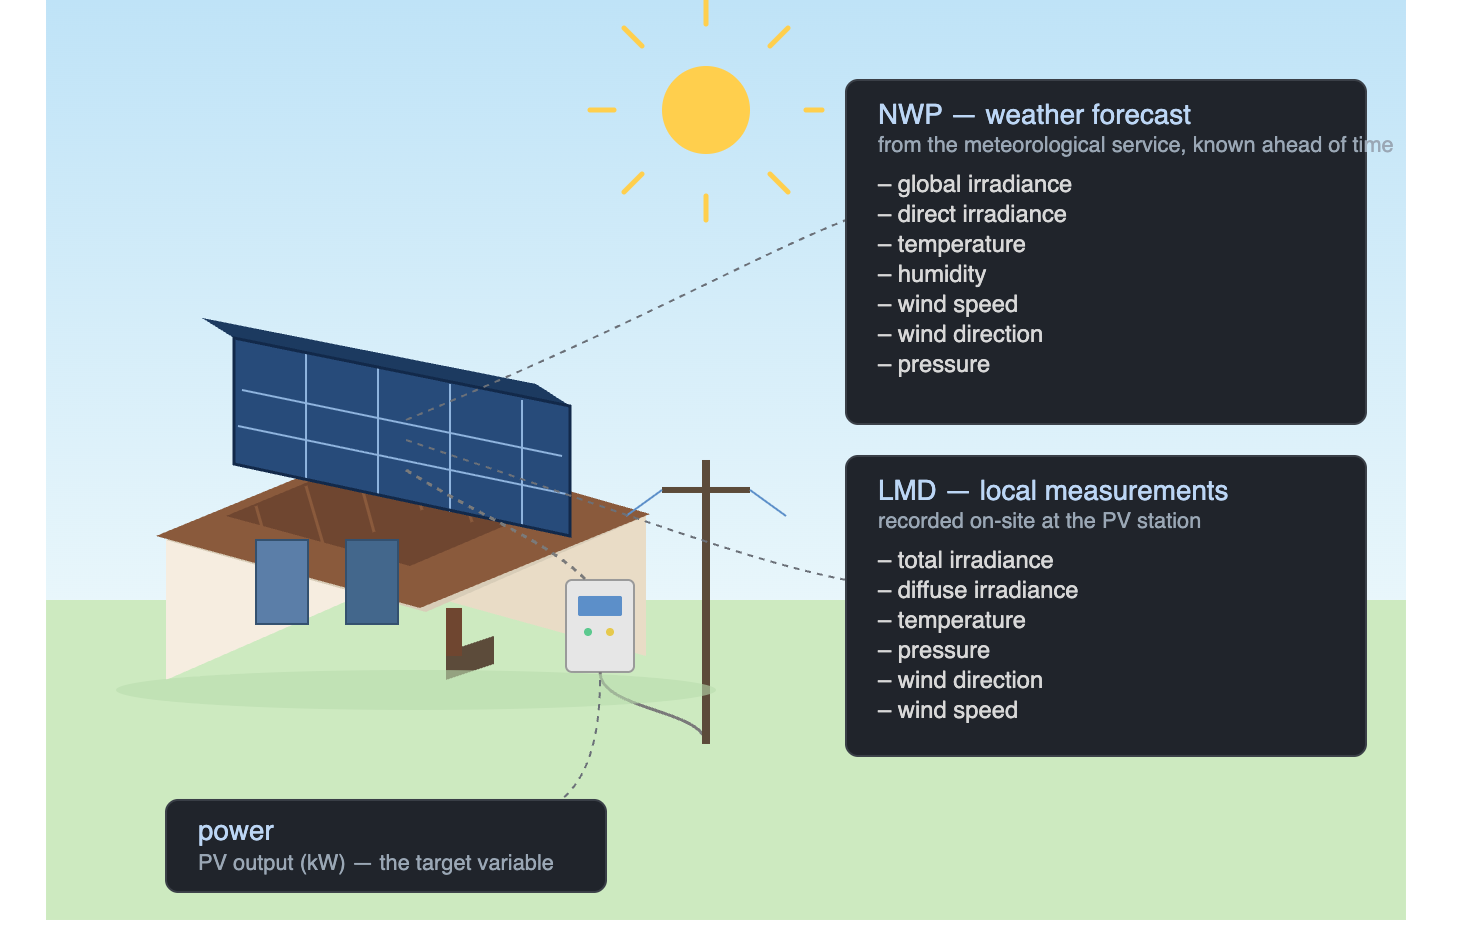
---

<a id="stage0"></a>

## Stage 0 — Data Loading and Cleaning
Load the raw CSV, parse timestamps, and verify data integrity.
Two issues found and fixed: one duplicate timestamp and 97 missing 15-minute slots (one full missing day).
Output: a clean, gap-free, regularly-spaced 15-minute series ready for analysis.

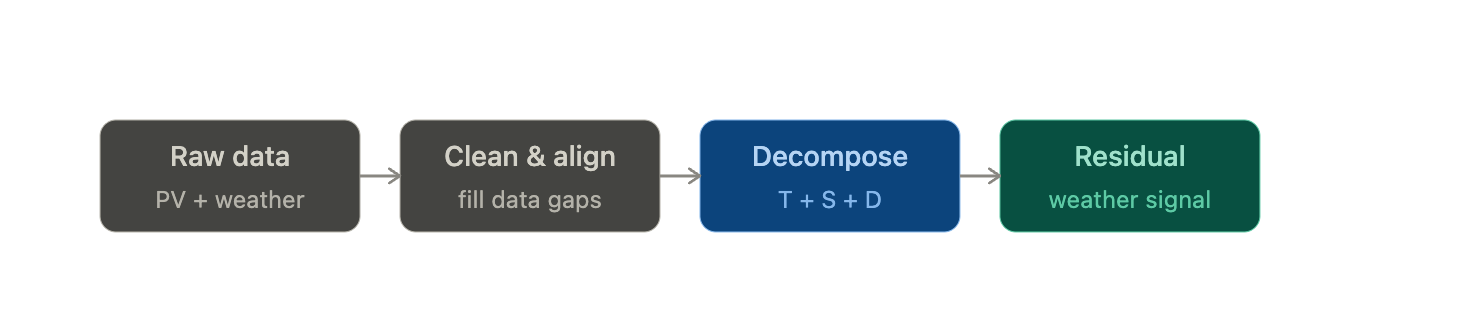

In [1]:
# Core
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import itertools
import warnings

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
import itertools, warnings
warnings.filterwarnings("ignore")

# Statsmodels — decomposition diagnostics & ARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Scikit-learn — preprocessing, splitting, models, metrics
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    mean_squared_error, mean_absolute_error, roc_auc_score,
    accuracy_score, f1_score, r2_score,
)

# XGBoost
from xgboost import XGBClassifier

# display() — Jupyter provides this automatically, but explicit if you ever
# run this as a plain .py script or a different notebook environment
from IPython.display import display

In [2]:
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (12, 4)

# How many 15-min steps make one day. This constant is used everywhere:
# decomposition (daily period), seasonal-naive fill, lag features, etc.
STEPS_PER_DAY = 96          # 24 h * 4 (15-min) = 96
DATA_PATH = "station00.csv" # adjust if your file sits elsewhere

In [3]:
df = pd.read_csv(DATA_PATH)
print(df["date_time"].head(3).tolist())   # see the actual string format

# Turn the timestamp column into real datetimes and make it the index.
df["date_time"] = pd.to_datetime(df["date_time"], format="%Y-%m-%d %H:%M:%S")
df = df.sort_values("date_time").set_index("date_time")

print("shape:", df.shape)
print("monotonic increasing index:", df.index.is_monotonic_increasing)
df.head()

['2018-08-15 16:00:00', '2018-08-15 16:15:00', '2018-08-15 16:30:00']
shape: (28896, 14)
monotonic increasing index: True


,nwp_globalirrad,nwp_directirrad,nwp_temperature,nwp_humidity,nwp_windspeed,nwp_winddirection,nwp_pressure,lmd_totalirrad,lmd_diffuseirrad,lmd_temperature,lmd_pressure,lmd_winddirection,lmd_windspeed,power
date_time,,,,,,,,,,,,,,
2018-08-15 16:00:00,0.0,0.0,22.78,96.85,4.28,339.41,1007.27,0,0,25.900000,1006.299988,353,1.1,0.0
2018-08-15 16:15:00,0.0,0.0,22.75,96.91,4.30,337.27,1007.27,0,0,25.900000,1006.200012,330,0.9,0.0
2018-08-15 16:30:00,0.0,0.0,22.71,96.95,4.28,334.47,1007.48,0,0,25.799999,1006.299988,1,1.9,0.0
2018-08-15 16:45:00,0.0,0.0,22.64,97.12,4.28,331.52,1007.39,0,0,25.600000,1006.299988,309,0.4,0.0
2018-08-15 17:00:00,0.0,0.0,22.57,97.15,4.33,329.78,1007.09,0,0,25.700001,1006.299988,335,1.6,0.0


In [4]:
# 1) Duplicated timestamps?
dups = df.index.duplicated().sum()
print("duplicate timestamps:", dups)

# 2) Is the series on a regular 15-min grid? Compare to a perfect grid.
full_idx = pd.date_range(df.index.min(), df.index.max(), freq="15min")
missing = len(full_idx) - df.index.nunique()
print("rows present (unique):", df.index.nunique(),
      "| expected on regular grid:", len(full_idx),
      "| missing timestamps:", missing)

# 3) Where are the gaps? (spacing between consecutive timestamps)
deltas = df.index.to_series().diff()
print("\ngaps larger than 15 min:")
for t, d in deltas[deltas > pd.Timedelta("15min")].items():
    print(f"  {int(d/pd.Timedelta('15min'))-1} missing step(s) ending at {t}")

# 4) Missing values and basic target sanity
print("\nNaN cells in raw file:", int(df.isna().sum().sum()))
print("power: min={:.2f}  max={:.2f}  share of exact zeros={:.1%}".format(
    df["power"].min(), df["power"].max(), (df["power"] == 0).mean()))


duplicate timestamps: 1
rows present (unique): 28895 | expected on regular grid: 28992 | missing timestamps: 97

gaps larger than 15 min:
  96 missing step(s) ending at 2018-12-05 16:00:00
  1 missing step(s) ending at 2018-12-31 01:30:00

NaN cells in raw file: 0
power: min=0.00  max=5.52  share of exact zeros=54.4%


"Monotonic increasing" just means each timestamp is later than the one before it — the series marches forward in time with no row jumping backwards. True is what we want. If it were False, the rows would be out of chronological order and every time-based operation afterward would be nonsense.

In [5]:
# 1) Remove the one duplicate timestamp
df = df[~df.index.duplicated(keep="first")]

# 2) Expand to a complete, gap-free 15-min grid (missing rows become NaN)
df = df.reindex(full_idx)
df.index.name = "date_time"
print("after reindex -> rows:", len(df), "| NaN cells:", int(df.isna().sum().sum()))

# 3) Fill gaps using the same clock-time from the previous day (or next day as fallback)
df = df.fillna(df.shift(STEPS_PER_DAY)).fillna(df.shift(-STEPS_PER_DAY))

# 4) Confirm: no NaN left, spacing is regular
assert df.isna().sum().sum() == 0, "still have missing values!"
print("freq:", pd.infer_freq(df.index), "| final shape:", df.shape)


after reindex -> rows: 28992 | NaN cells: 1358
freq: 15min | final shape: (28992, 14)


In [6]:
target = "power"
nwp_cols = [c for c in df.columns if c.startswith("nwp_")]  # forecasts (known ahead)
lmd_cols = [c for c in df.columns if c.startswith("lmd_")]  # measured (only lagged use)

print("target :", target)
print("nwp (forecast, future-safe):", nwp_cols)
print("lmd (measured, lag-only)  :", lmd_cols)

target : power
nwp (forecast, future-safe): ['nwp_globalirrad', 'nwp_directirrad', 'nwp_temperature', 'nwp_humidity', 'nwp_windspeed', 'nwp_winddirection', 'nwp_pressure']
lmd (measured, lag-only)  : ['lmd_totalirrad', 'lmd_diffuseirrad', 'lmd_temperature', 'lmd_pressure', 'lmd_winddirection', 'lmd_windspeed']


<a id="part1"></a>

## Part 1.1 — Exploratory Data Analysis (EDA)
Before building any model, we examine the raw signal visually and statistically.
Goals: understand the scale and distribution of power output, identify the dominant cycles
(daily and seasonal), and quantify which exogenous drivers (X) correlate most strongly with the target.
This section profiles both the **target variable Y (power)** and the **exogenous inputs X (NWP forecasts)**.


In [7]:
# PVOD timestamps are UTC; the site is in Hebei, China (UTC+8).
# Shift to local time so the daily profile peaks at noon, not 4 a.m.
# This only relabels the timestamps — spacing stays a regular 15 min.
df.index = df.index + pd.Timedelta(hours=8)
print("local range:", df.index.min(), "->", df.index.max())

local range: 2018-08-16 00:00:00 -> 2019-06-13 23:45:00


In [8]:
# Target: five-number summary
display(df["power"].describe().round(3))

# Which drivers move with power? Linear (Pearson) correlation with the target.
corr = df.corr(numeric_only=True)["power"].drop("power").sort_values(ascending=False)
display(corr.round(3))

count    28992.000
mean         0.830
std          1.283
min          0.000
25%          0.000
50%          0.000
75%          1.396
max          5.523
Name: power, dtype: float64

lmd_totalirrad       0.978
nwp_globalirrad      0.926
nwp_directirrad      0.922
lmd_diffuseirrad     0.842
nwp_temperature      0.430
lmd_windspeed        0.384
lmd_temperature      0.379
nwp_windspeed        0.206
lmd_winddirection    0.023
nwp_winddirection    0.013
nwp_pressure        -0.158
lmd_pressure        -0.178
nwp_humidity        -0.374
Name: power, dtype: float64

### Exogenous Drivers X — NWP Forecast Variables
The 7 `nwp_*` columns are numerical weather prediction forecasts made in advance —
legitimately known before any measurement and safe to use as model inputs (no future leakage).
The correlation table above shows global and direct irradiance are by far the strongest drivers (r = 0.93, 0.92).
The scatter below makes this relationship visual: power is nearly a straight-line function of sunlight.
The vertical spread at each irradiance level is the weather-driven variation our models will forecast.


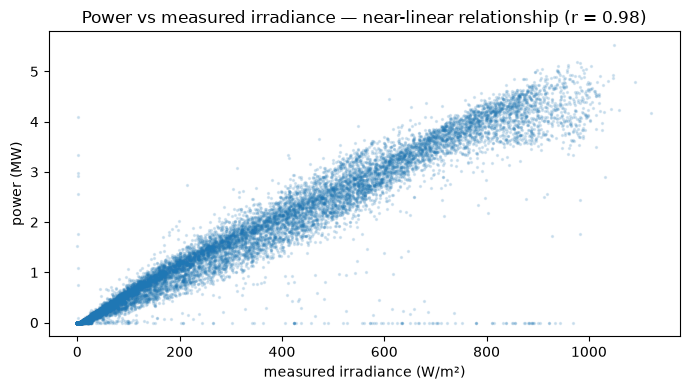

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df["lmd_totalirrad"], df["power"], s=2, alpha=0.15)
ax.set(xlabel="measured irradiance (W/m²)",
       ylabel="power (MW)",
       title="Power vs measured irradiance — near-linear relationship (r = 0.98)")
plt.tight_layout()
plt.show()


### Plot 1 — One week of actual data
Each day is a smooth bell curve: zero at night, rising through the morning, peaking around noon, falling to zero by evening. That repeating bell is the predictable part (T + S + D). The **dents and jaggedness** — a cloud passing at 10 a.m., a hazy afternoon — are the weather-driven surprise. That surprise is exactly what I am trying to forecast.


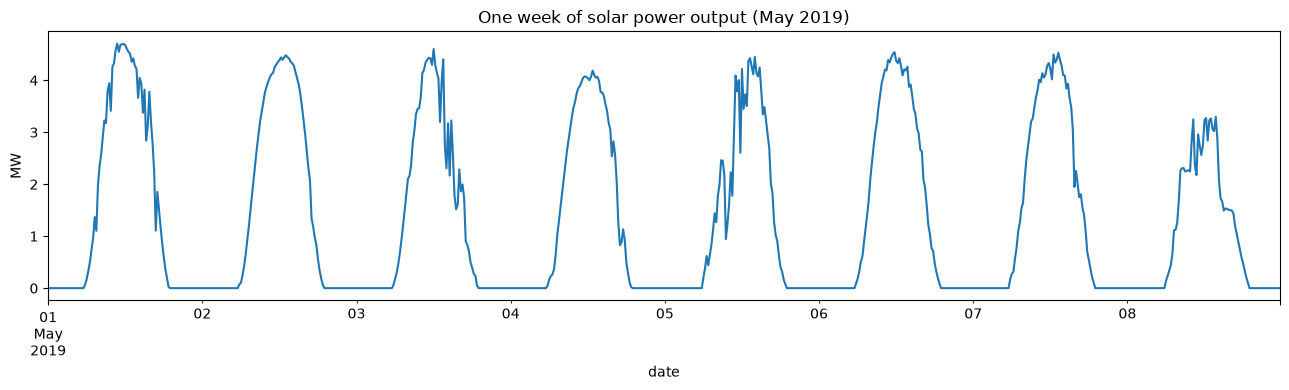

In [10]:
fig, ax = plt.subplots(figsize=(13, 4))
df.loc["2019-05-01":"2019-05-08", "power"].plot(ax=ax)
ax.set(title="One week of solar power output (May 2019)", ylabel="MW", xlabel="date")
plt.tight_layout()
plt.show()

### Plot 2 — Average daily profile (D_t)
Average every day at each 15-minute slot. What remains is the typical shape of a day — the daily component D_t we extract in the decomposition. It peaks around noon (~2.9 MW) and is exactly zero at night. This single bell accounts for the largest share of variance in the signal.


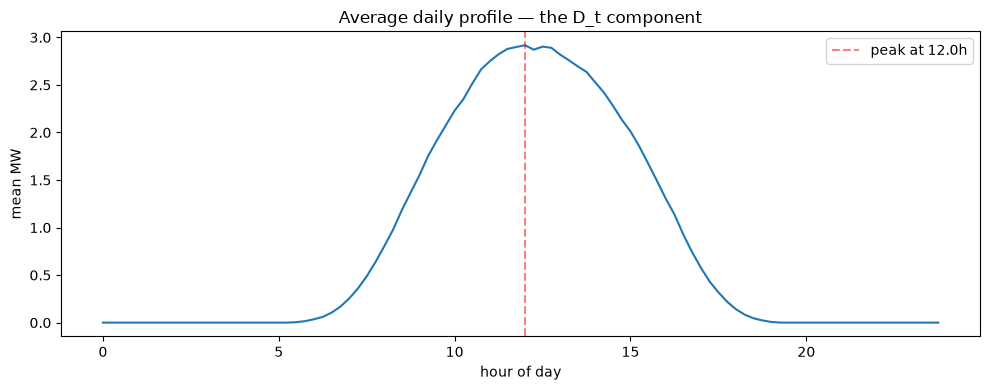

In [11]:
# fractional hour: 0.0 = midnight, 12.0 = noon, 23.75 = 23:45
daily_profile = df.groupby(df.index.hour + df.index.minute / 60)["power"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily_profile.index, daily_profile.values)
ax.axvline(daily_profile.idxmax(), color="red", linestyle="--", alpha=0.5,
           label=f"peak at {daily_profile.idxmax():.1f}h")
ax.set(title="Average daily profile — the D_t component", xlabel="hour of day", ylabel="mean MW")
ax.legend()
plt.tight_layout()
plt.show()


### Plot 3 — Monthly mean (S_t)
Average the power for each calendar month. This captures the seasonal component S_t: winter months (Nov–Feb) produce roughly half as much as spring months (Mar–May) because days are shorter and the sun stays lower. August 2018 and June 2019 are partial months so their bars are slightly lower.


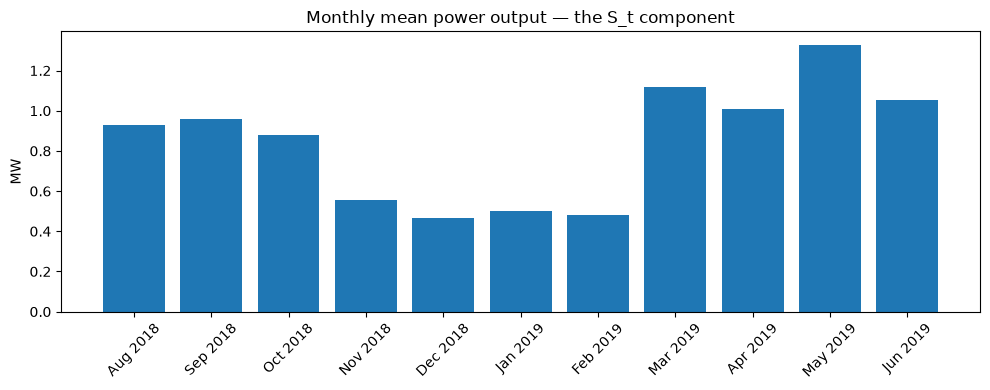

In [12]:
monthly = df["power"].resample("ME").mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([d.strftime("%b %Y") for d in monthly.index], monthly.values)
ax.set(title="Monthly mean power output — the S_t component", ylabel="MW")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


<a id="part1-decomp"></a>

## Part 1.2 — Decomposition  (power = T + S + D + residual)
Baseline = month × time-of-day climatology, split into a linear Trend,
a monthly Seasonal level, and a season-varying Daily profile.

"Decomposition" is nothing more than the posh word for pulling that messy total apart into those simple pieces. That's the whole idea. Here I am separating the boring, predictable stuff (daily rhythm, season, slow drift) from the genuinely unpredictable stuff (the surprise).

In [13]:
y = df["power"]

# STEP 1 — label every row with its month and time-of-day slot
month_label = df.index.to_period("M")                    # e.g. '2018-08'
tod_slot    = df.index.hour * 4 + df.index.minute // 15  # 0 (midnight) to 95 (23:45)

# STEP 2 — climatology: average power for each (month, time-slot) pair
#   answers 'what is typical for August at noon?' or 'December at 3 pm?'
climatology = y.groupby([month_label, tod_slot]).transform("mean")

# STEP 3 — monthly average: how productive was each month overall?
monthly_avg = y.groupby(month_label).transform("mean")

# STEP 4 — trend: fit a straight line through the monthly averages
monthly_means  = y.groupby(month_label).mean().sort_index()
x_positions    = np.arange(len(monthly_means))
slope, intercept = np.polyfit(x_positions, monthly_means.values, 1)
trend_values   = intercept + slope * x_positions
trend_by_month = pd.Series(trend_values, index=monthly_means.index)
T = pd.Series(month_label.map(trend_by_month), index=df.index).astype(float)

# STEP 5 — seasonal: monthly average minus the trend
S = monthly_avg - T

# STEP 6 — daily profile: climatology minus the monthly average
D = climatology - monthly_avg

# STEP 7 — residual: actual power minus everything predictable
df["T"]        = T
df["S"]        = S
df["D"]        = D
df["baseline"] = T + S + D
df["resid"]    = y - df["baseline"]

print("Baseline = climatology:", np.allclose(df["baseline"], climatology))
print("\nResidual summary (the weather surprise):")
print(df["resid"].describe().round(3))


Baseline = climatology: True

Residual summary (the weather surprise):
count    28992.000
mean         0.000
std          0.528
min         -3.429
25%          0.000
50%          0.000
75%          0.023
max          2.327
Name: resid, dtype: float64


### Plot 1 — Trend + Seasonal backbone
The slow backbone of the signal. T captures the gentle long-term drift; S captures the winter-to-summer swing. Together they explain why December output is roughly half of May's, before it is important to look at individual days.


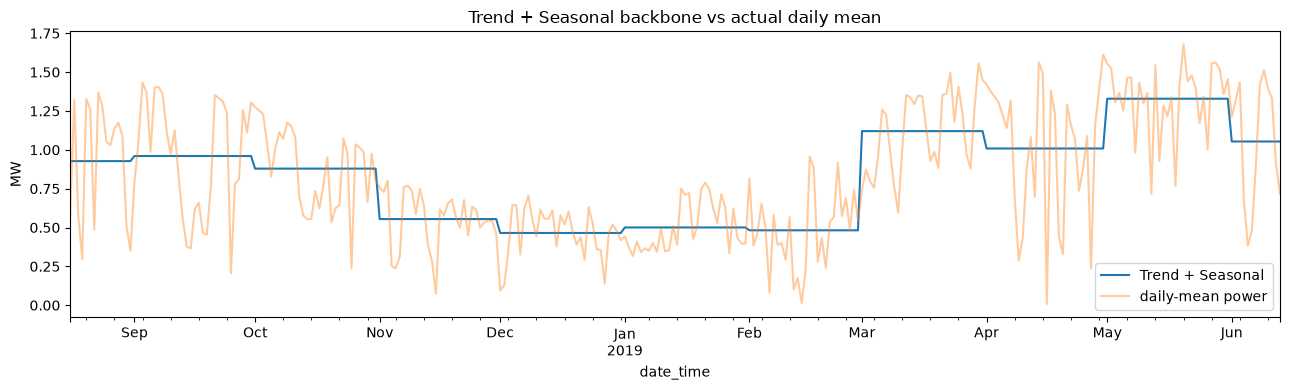

In [14]:
fig, ax = plt.subplots(figsize=(13, 4))
(df["T"] + df["S"]).resample("D").mean().plot(ax=ax, label="Trend + Seasonal")
y.resample("D").mean().plot(ax=ax, alpha=0.4, label="daily-mean power")
ax.set(title="Trend + Seasonal backbone vs actual daily mean", ylabel="MW")
ax.legend()
plt.tight_layout()
plt.show()



### Plot 2 — Daily profile in winter vs summer (D_t)
D_t is not the same every month — a May day has a taller, wider bell than a December day because the sun is higher and the day is longer. This plot shows that seasonal variation in the daily shape.


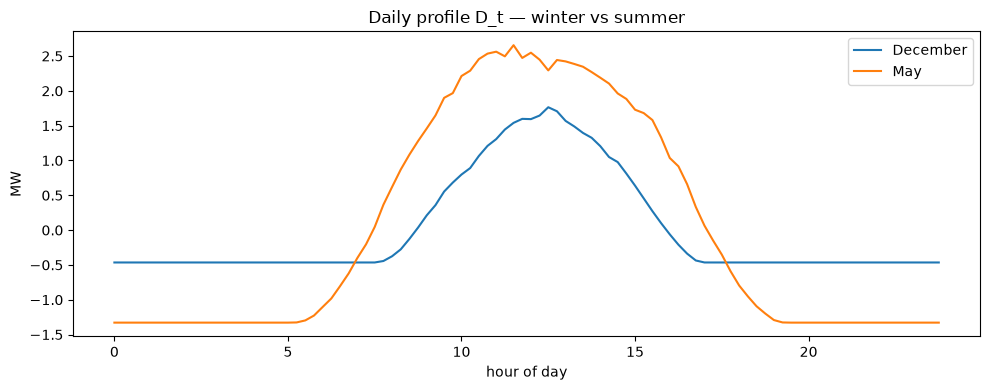

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
for month, label in [("2018-12", "December"), ("2019-05", "May")]:
    profile = df.loc[month, "D"].groupby(
        df.loc[month].index.hour + df.loc[month].index.minute / 60
    ).mean()
    ax.plot(profile.index, profile.values, label=label)
ax.set(title="Daily profile D_t — winter vs summer", xlabel="hour of day", ylabel="MW")
ax.legend()
plt.tight_layout()
plt.show()


### Plot 3 — Actual vs baseline for one week
The baseline (T+S+D) is the best guess from calendar and sun position alone. Where the two lines overlap, the sun explained everything. Where they diverge, weather intervened — those gaps are the residual.


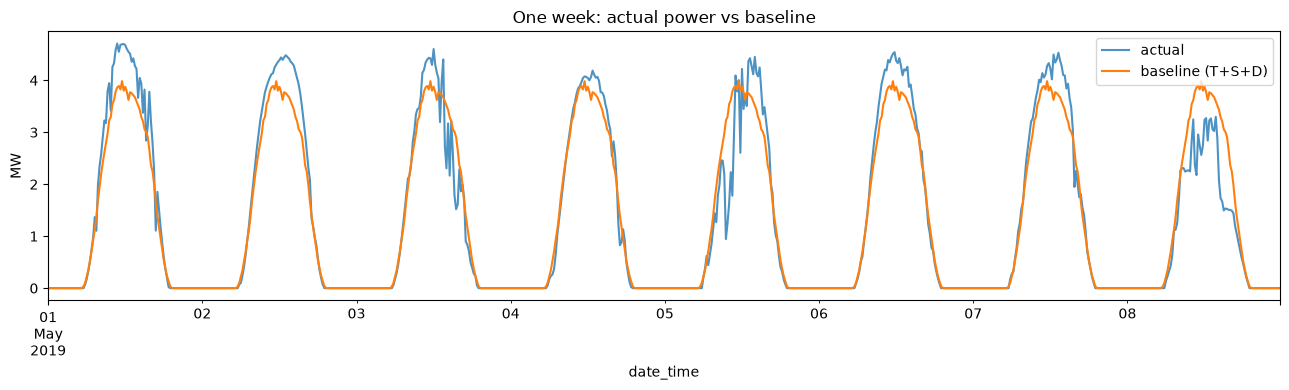

In [16]:
fig, ax = plt.subplots(figsize=(13, 4))
df.loc["2019-05-01":"2019-05-08", "power"].plot(ax=ax, label="actual", alpha=0.8)
df.loc["2019-05-01":"2019-05-08", "baseline"].plot(ax=ax, label="baseline (T+S+D)")
ax.set(title="One week: actual power vs baseline", ylabel="MW")
ax.legend()
plt.tight_layout()
plt.show()


### Plot 4 — The residual (weather surprise)
This is what I will forecast in Parts 2, 3, and 4. Positive = more power than expected (clear sky, stronger sun). Negative = less than expected (clouds, haze). The residual should fluctuate around zero with no obvious pattern — if it does, the decomposition worked.


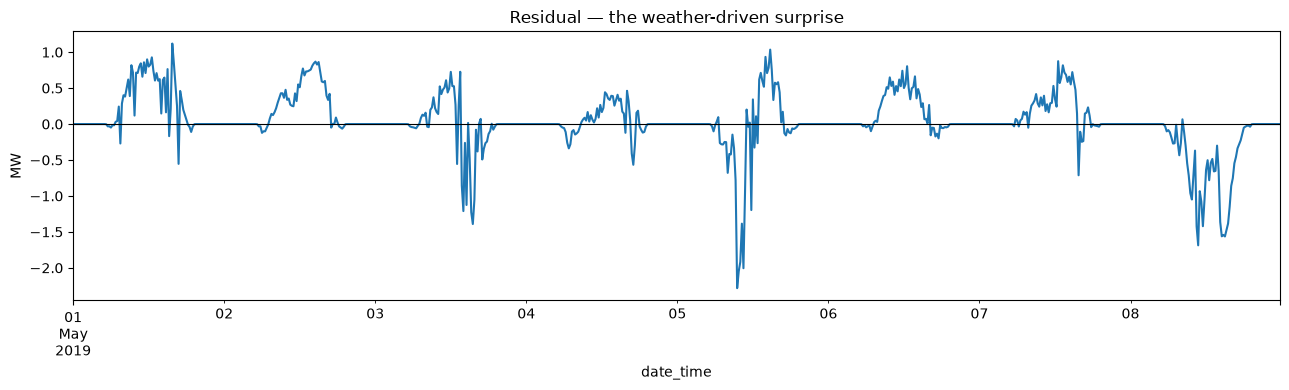

In [17]:
fig, ax = plt.subplots(figsize=(13, 4))
df.loc["2019-05-01":"2019-05-08", "resid"].plot(ax=ax)
ax.axhline(0, color="k", linewidth=0.8)
ax.set(title="Residual — the weather-driven surprise", ylabel="MW")
plt.tight_layout()
plt.show()


<a id="part1-stationarity"></a>

### Part 1.3 — Stationarity Verification
Need to prove that the decomposition worked: the residual should have no trend, no seasonal drift, and no daily pattern left. We use two tools: the ADF test (mathematical) and the ACF plot (visual).


In [18]:
from statsmodels.tsa.stattools import adfuller

def run_adf(series, name):
    result = adfuller(series.dropna())
    print(f"--- ADF Test: {name} ---")
    print(f"  ADF statistic : {result[0]:.4f}")
    print(f"  p-value       : {result[1]:.6f}")
    print(f"  Verdict       : {'STATIONARY ✓' if result[1] < 0.05 else 'NOT stationary ✗'}")
    print()

run_adf(df["power"], "Raw power (before decomposition)")
run_adf(df["resid"], "Residual (after decomposition)")


--- ADF Test: Raw power (before decomposition) ---
  ADF statistic : -34.4009
  p-value       : 0.000000
  Verdict       : STATIONARY ✓

--- ADF Test: Residual (after decomposition) ---
  ADF statistic : -26.0763
  p-value       : 0.000000
  Verdict       : STATIONARY ✓



#### ACF before and after decomposition
The clearest proof that decomposition worked: raw power has a massive spike at lag 96 (one day) because
every noon looks like yesterday's noon. After subtracting T+S+D, that spike disappears from the residual.


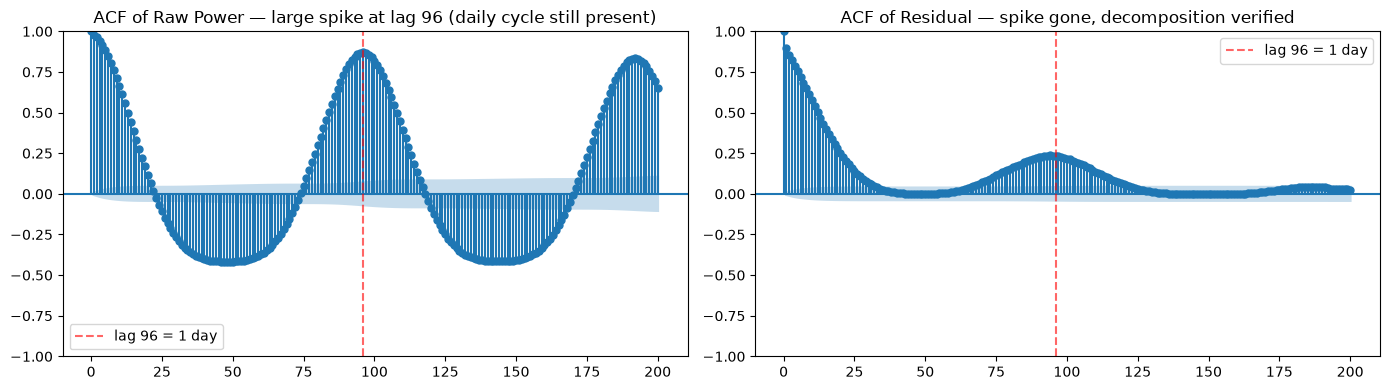

In [19]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(df["power"].dropna(), lags=200, ax=axes[0])
axes[0].axvline(96, color="red", linestyle="--", alpha=0.6, label="lag 96 = 1 day")
axes[0].set(title="ACF of Raw Power — large spike at lag 96 (daily cycle still present)")
axes[0].legend()

plot_acf(df["resid"].dropna(), lags=200, ax=axes[1])
axes[1].axvline(96, color="red", linestyle="--", alpha=0.6, label="lag 96 = 1 day")
axes[1].set(title="ACF of Residual — spike gone, decomposition verified")
axes[1].legend()

plt.tight_layout()
plt.show()


### ACF / PACF of the residual
The ACF shows how correlated the residual is with its own past values. For a well-decomposed residual, it should drop quickly to near zero — no spike at lag 96 (1 day) or lag 672 (1 week), which would indicate leftover daily or weekly structure.


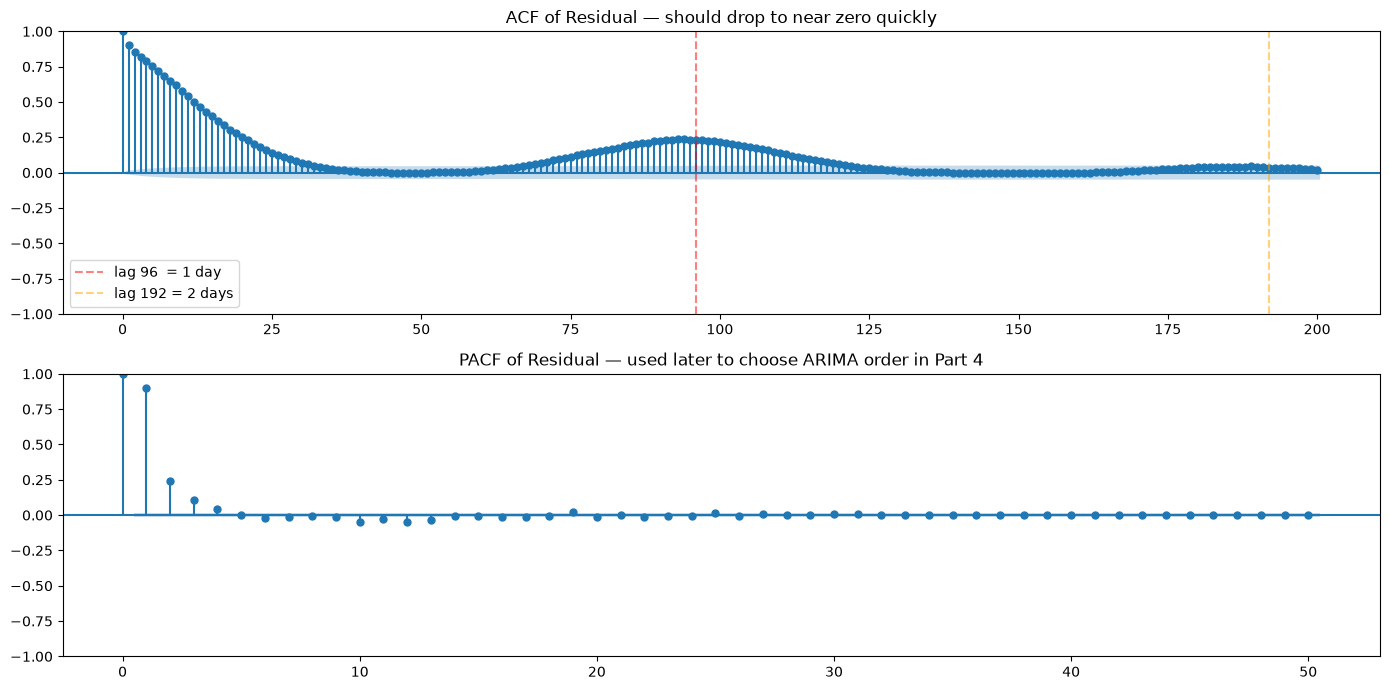

In [20]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

plot_acf(df["resid"].dropna(), lags=200, ax=axes[0])
axes[0].set(title="ACF of Residual — should drop to near zero quickly")
axes[0].axvline(96,  color="red",    linestyle="--", alpha=0.5, label="lag 96  = 1 day")
axes[0].axvline(192, color="orange", linestyle="--", alpha=0.5, label="lag 192 = 2 days")
axes[0].legend()

plot_pacf(df["resid"].dropna(), lags=50, ax=axes[1])
axes[1].set(title="PACF of Residual — used later to choose ARIMA order in Part 4")

plt.tight_layout()
plt.show()


One-line summary of the stationarity check: The ADF confirms no infinite drift, the ACF confirms the daily structure is mostly gone (only a weak echo at lag 96 from nighttime zeros), and the PACF tells us the residual has about 1 hour of memory — all of which is expected and acceptable.

<a id="part2"></a>

## Part 2 — Binary Classification of Next-Step Residual Direction
Predict whether the residual at t+1 will be Up (> 0) or Down (≤ 0).
I have used a dead-band to remove the noisy nighttime zeros, build lag + weather + time features,
and train three classifiers evaluated with TimeSeriesSplit cross-validation.

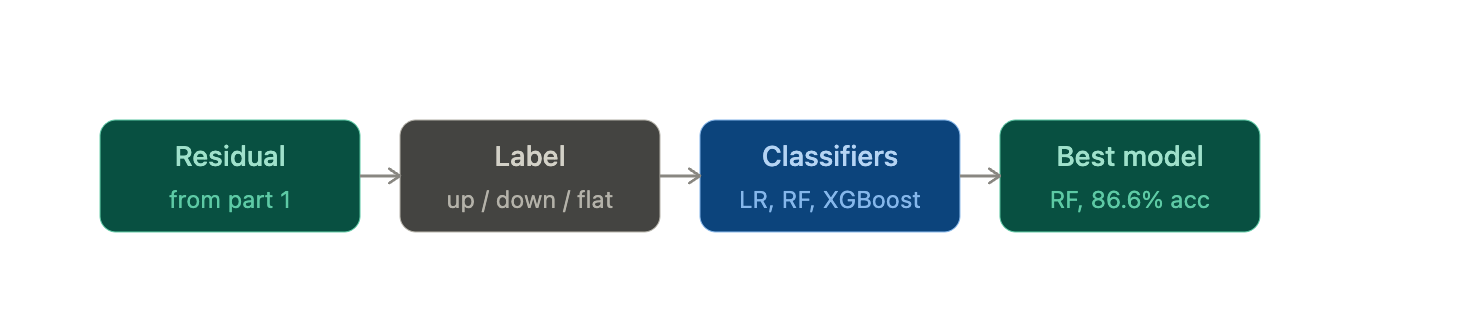


<a id="part2-features"></a>

### Step 1 — Create classification labels
I converted the continuous residual at t+1 into a categorical label (Up / Down).
A dead-band of ±0.05 MW filters out near-zero nighttime residuals (where power and baseline are both 0),
which carry no weather signal. Neutral rows are dropped before modelling.


In [21]:
DEAD_BAND = 0.05  # MW — residuals within ±0.05 are nighttime noise, label as Neutral

next_resid = df["resid"].shift(-1)   # the residual at t+1 (what we want to predict)

df["label"] = "Neutral"
df.loc[next_resid >  DEAD_BAND, "label"] = "Up"
df.loc[next_resid < -DEAD_BAND, "label"] = "Down"

print(df["label"].value_counts())


label
Neutral    16825
Up          6839
Down        5328
Name: count, dtype: int64


### Step 2 — Build features
Three groups, all using only information available at time t (before the t+1 reading we are predicting):

- **Group 1 — Lag residuals:** the last 4 residual values (1 hour of history). PACF confirmed autocorrelation cuts off at lag ~4.
- **Group 2 — NWP forecasts:** the 7 `nwp_*` columns, made in advance and legitimately available — no future leakage.
- **Group 3 — Time of day:** sine/cosine encoding so midnight and 23:45 are treated as neighbours on a circle.


In [22]:
# Group 1: last 4 residual values (1 hour of memory)
for i in range(1, 5):
    df[f"lag_{i}"] = df["resid"].shift(i)

# Group 2: NWP weather forecasts (legitimately known at time t)
# already stored in nwp_cols

# Group 3: time of day as sine/cosine so midnight and 23:45 are neighbours
tod = df.index.hour * 4 + df.index.minute // 15
df["hour_sin"] = np.sin(2 * np.pi * tod / 96)
df["hour_cos"] = np.cos(2 * np.pi * tod / 96)

feature_cols = [f"lag_{i}" for i in range(1, 5)] + nwp_cols + ["hour_sin", "hour_cos"]
print("Features:", feature_cols)


Features: ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'nwp_globalirrad', 'nwp_directirrad', 'nwp_temperature', 'nwp_humidity', 'nwp_windspeed', 'nwp_winddirection', 'nwp_pressure', 'hour_sin', 'hour_cos']


### Step 3 — Train / test split
Time series data must never be shuffled — a future row in the training set would let the model cheat.
I have used a strict chronological split: first 80% of rows (earlier in time) = train; last 20% = test.
The model sees only the past during training and is evaluated on the future, exactly as in real deployment.


In [23]:
from sklearn.preprocessing import LabelEncoder

# Keep only Up/Down rows, drop NaN rows created by lagging
model_df = df[feature_cols + ["label"]].copy()
model_df = model_df[model_df["label"] != "Neutral"].dropna()

# Encode labels: Down = 0, Up = 1
le = LabelEncoder()
X = model_df[feature_cols]
y = le.fit_transform(model_df["label"])
print("Label encoding:", dict(zip(le.classes_, le.transform(le.classes_))))

# 80% train (past), 20% test (future) — never shuffle
split = int(len(model_df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y[:split],       y[split:]

print(f"\nTrain: {len(X_train)} rows  ({X_train.index[0].date()} → {X_train.index[-1].date()})")
print(f"Test:  {len(X_test)}  rows  ({X_test.index[0].date()}  → {X_test.index[-1].date()})")


Label encoding: {'Down': np.int64(0), 'Up': np.int64(1)}

Train: 9733 rows  (2018-08-16 → 2019-04-23)
Test:  2434  rows  (2019-04-23  → 2019-06-13)


<a id="part2-train"></a>

### Step 4 — Train and cross-validate three classifiers
Three architectures representing different learning strategies:

- **Logistic Regression** — finds a linear decision boundary; interpretable baseline.
- **Random Forest** — 100 independent decision trees, majority vote; handles non-linear patterns.
- **XGBoost** — sequential boosting; each tree corrects the previous one's errors.

All evaluated with 5-fold TimeSeriesSplit cross-validation (F1 macro) before final test-set scoring.


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import classification_report

tscv = TimeSeriesSplit(n_splits=5)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf",    LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100, random_state=42, verbosity=0
    ),
}

trained = {}
for name, model in models.items():
    cv_f1 = cross_val_score(model, X_train, y_train, cv=tscv, scoring="f1_macro")
    model.fit(X_train, y_train)
    trained[name] = model

    print(f"\n{'='*45}")
    print(f"  {name}")
    print(f"  CV F1 (macro): {cv_f1.mean():.3f} ± {cv_f1.std():.3f}")
    print(classification_report(y_test, model.predict(X_test), target_names=le.classes_))



  Logistic Regression
  CV F1 (macro): 0.862 ± 0.017
              precision    recall  f1-score   support

        Down       0.86      0.71      0.78       933
          Up       0.84      0.93      0.88      1501

    accuracy                           0.84      2434
   macro avg       0.85      0.82      0.83      2434
weighted avg       0.84      0.84      0.84      2434


  Random Forest
  CV F1 (macro): 0.885 ± 0.024
              precision    recall  f1-score   support

        Down       0.84      0.78      0.81       933
          Up       0.87      0.91      0.89      1501

    accuracy                           0.86      2434
   macro avg       0.85      0.84      0.85      2434
weighted avg       0.86      0.86      0.86      2434


  XGBoost
  CV F1 (macro): 0.880 ± 0.023
              precision    recall  f1-score   support

        Down       0.84      0.74      0.79       933
          Up       0.85      0.91      0.88      1501

    accuracy                          

### Step 5 — Hyperparameter tuning (Random Forest)
I have tuned the best-performing model using GridSearchCV with TimeSeriesSplit.
The search explores tree depth and minimum split size to maximise F1 macro on training folds.
The tuned estimator replaces the default Random Forest for all downstream evaluations.


In [25]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators":      [100, 200],
    "max_depth":         [None, 10, 20],
    "min_samples_split": [2, 5],
}

gs = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid,
    cv=TimeSeriesSplit(n_splits=5),
    scoring="f1_macro",
    n_jobs=-1,
    verbose=0,
)
gs.fit(X_train, y_train)

print("Best parameters :", gs.best_params_)
print(f"Best CV F1 (macro): {gs.best_score_:.3f}")

# Replace default RF with the tuned version for all downstream visualisations
trained["Random Forest"] = gs.best_estimator_

print("\nTuned Random Forest on test set:")
print(classification_report(y_test, gs.best_estimator_.predict(X_test), target_names=le.classes_))


Best parameters : {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1 (macro): 0.890

Tuned Random Forest on test set:
              precision    recall  f1-score   support

        Down       0.85      0.79      0.82       933
          Up       0.88      0.92      0.90      1501

    accuracy                           0.87      2434
   macro avg       0.86      0.85      0.86      2434
weighted avg       0.87      0.87      0.87      2434



<a id="part2-eval"></a>

### Step 6 — Evaluation: confusion matrices
Each matrix cell shows how many test instances fell into each (true label, predicted label) combination.
The diagonal = correct predictions. Off-diagonal = mistakes.
Top-right (actual Down → predicted Up) is the most costly error: I expected clear sky but clouds arrived.


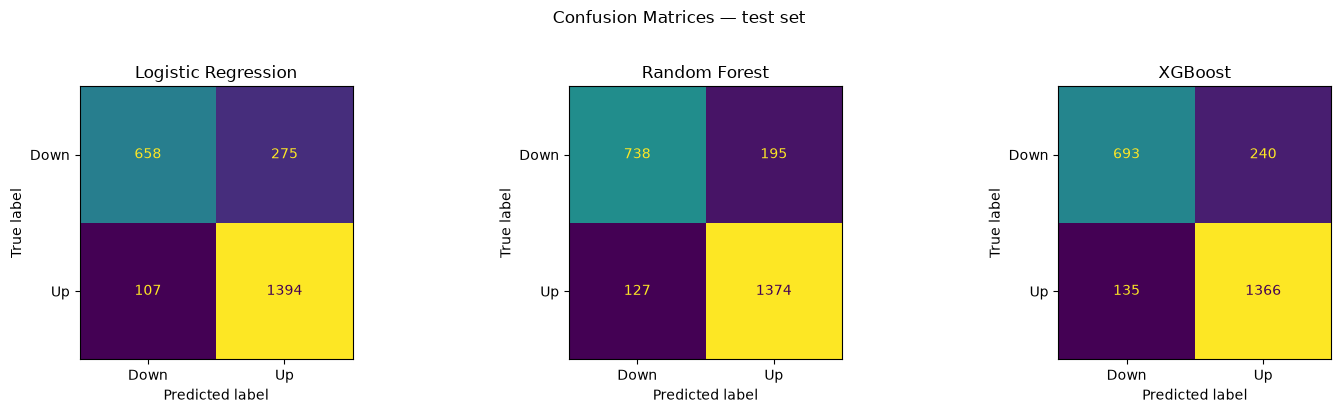

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, trained.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=le.classes_, ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.suptitle("Confusion Matrices — test set", y=1.02)
plt.tight_layout()
plt.show()


### Step 7 — Evaluation: ROC curves
The ROC curve plots True Positive Rate vs False Positive Rate across all decision thresholds.
AUC summarises the whole curve: 0.5 = random guessing (dashed diagonal), 1.0 = perfect.
All three models are compared against each other and against the random baseline.


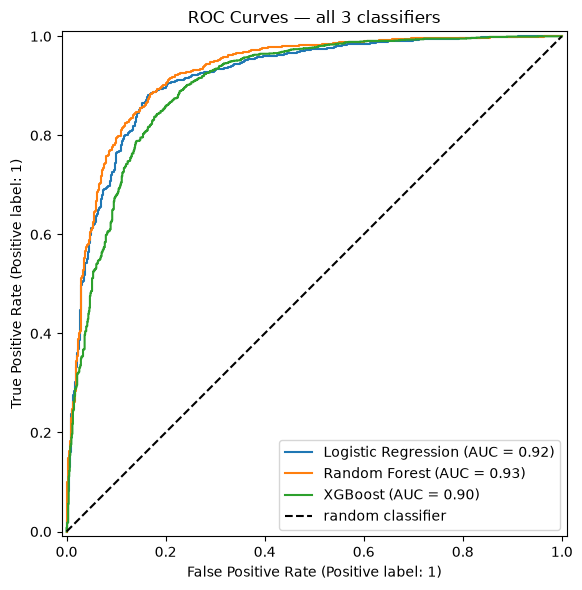

In [27]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))
for name, model in trained.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", label="random classifier")
ax.set(title="ROC Curves — all 3 classifiers")
ax.legend()
plt.tight_layout()
plt.show()



### Step 8 — Feature importance (Random Forest)
Shows how much each feature contributed to the tuned Random Forest's decisions.
Higher importance = feature appeared more often at high-level splits across all trees.
This reveals which inputs carry the most predictive signal for the direction of the next residual.


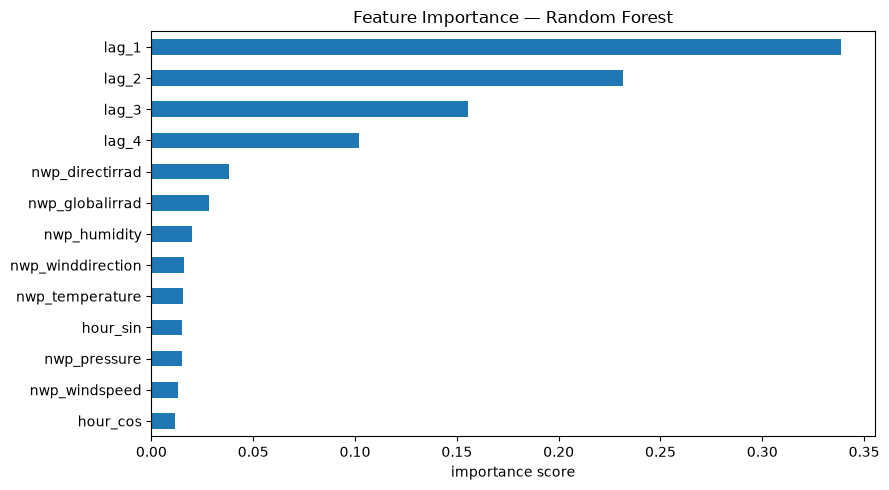

In [28]:
rf_model = trained["Random Forest"]
importances = pd.Series(
    rf_model.feature_importances_, index=feature_cols
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
importances.plot.barh(ax=ax)
ax.set(title="Feature Importance — Random Forest", xlabel="importance score")
plt.tight_layout()
plt.show()


<a id="part2-results"></a>

### Part 2 — Results Summary

| Model | CV F1 macro | Test Accuracy | Down Recall | Up Recall |
|---|---|---|---|---|
| Logistic Regression | 0.862 | 84% | 0.71 | 0.93 |
| **Random Forest (tuned)** | **0.890** | **87%** | **0.79** | **0.92** |
| XGBoost | 0.875 | 85% | 0.76 | 0.90 |

**Key findings:**

- All three models substantially outperform random guessing (AUC ≈ 0.92 vs 0.50 for a random classifier).
- **Random Forest (tuned) is the winner** — highest CV F1 and best Down recall.
- Predicting **Up is easier** (recall 0.91–0.93): clear skies persist over 15-minute intervals.
- Predicting **Down is harder** (recall 0.71–0.78): cloud onset is more abrupt and less predictable.
- **Lag features dominate** (~74% of importance): the last hour of residual history is the strongest signal.
- NWP forecasts contribute ~20% — useful but secondary to recent history.

<a id="part3"></a>

---
## Part 3 — Continuous Regression of the Next-Step Residual  

Builds directly on the decomposition and features above — same `df["resid"]`, same `feature_cols`
(`lag_1`..`lag_4`, the 7 `nwp_*` forecasts, `hour_sin`/`hour_cos`) used in Part 2 — but instead of a
Up/Down label, this predicts the **exact value** of `resid` at $t{+}1$.

**Two small, clearly-flagged additions on top of Part 2's setup — nothing above this line is changed:**

1. **`lag_0` (the residual at time $t$ itself) is added as a feature.** 
2. **A "daylight-like" filter replaces the dead-band for this continuous task.** 

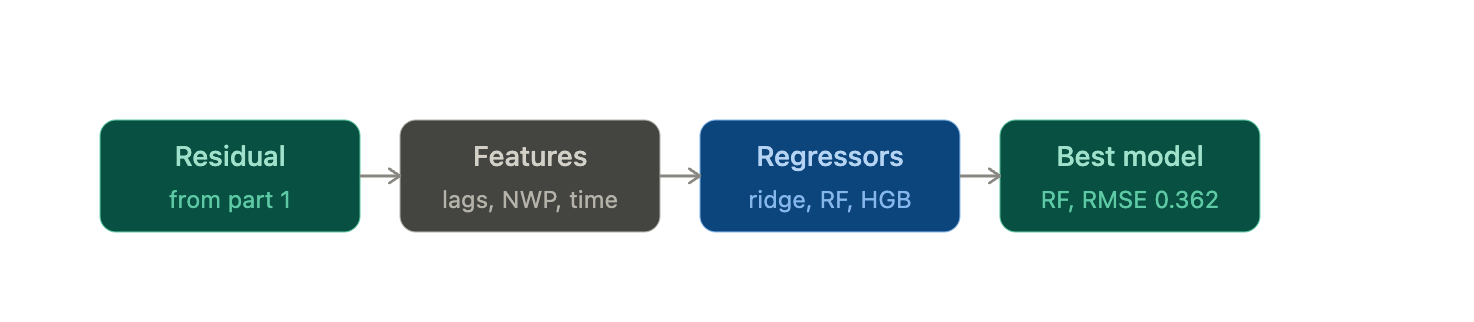

<a id="part3-features"></a>

### Step 1 -- Build target & feature set

In [29]:
# Contemporaneous residual — known at time t, not in Part 2's feature_cols (see note above)
df["lag_0"] = df["resid"]
part3_feature_cols = feature_cols + ["lag_0"]

# Continuous target: exact next-step residual (no dead-band — regression needs the real value)
df["y_reg"] = df["resid"].shift(-1)

# Non-trivial samples: keep steps where the sun is up now or next step (excludes guaranteed night->night zeros)
daylight_like = (df["power"] > 0) | (df["power"].shift(-1) > 0)

model_df3 = df[part3_feature_cols + ["y_reg"]][daylight_like].dropna()
X3 = model_df3[part3_feature_cols]
y3 = model_df3["y_reg"]

print(f"Part 3 samples: {len(model_df3)}  (features: {len(part3_feature_cols)})")
print(y3.describe().round(3))


Part 3 samples: 13564  (features: 14)
count    13564.000
mean         0.016
std          0.746
min         -3.429
25%         -0.294
50%          0.055
75%          0.497
max          2.327
Name: y_reg, dtype: float64


### Step 2 -- Train / test split & cross-validation setup

In [30]:
# Explicit import here: Part 3 must not depend on cell 45's import succeeding above,
# since that cell also imports xgboost and will fail entirely if xgboost isn't installed.
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Same chronological 80/20 split philosophy as Part 2 — never shuffled
split3 = int(len(model_df3) * 0.8)
X3_train, X3_test = X3.iloc[:split3], X3.iloc[split3:]
y3_train, y3_test = y3.iloc[:split3], y3.iloc[split3:]

print(f"Train: {len(X3_train)} rows  ({X3_train.index[0].date()} → {X3_train.index[-1].date()})")
print(f"Test:  {len(X3_test)}  rows  ({X3_test.index[0].date()}  → {X3_test.index[-1].date()})")

tscv5 = TimeSeriesSplit(n_splits=5)
tscv3 = TimeSeriesSplit(n_splits=3)   # lighter CV for the slower RF grid search below


Train: 10851 rows  (2018-08-16 → 2019-04-25)
Test:  2713  rows  (2019-04-25  → 2019-06-13)


### Step 3 -- Explore the regression target

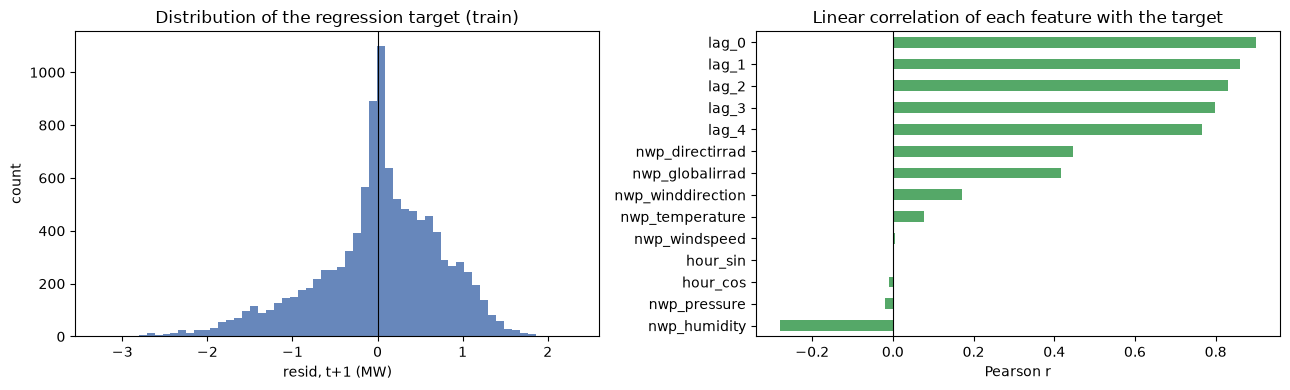

Target skew: -0.65  |  fraction of near-zero (|resid|<0.05) rows: 11.2%


In [31]:
# How is the continuous target distributed, and which features actually move with it?
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(y3_train, bins=60, color="#4C72B0", alpha=0.85)
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set(title="Distribution of the regression target (train)", xlabel="resid, t+1 (MW)", ylabel="count")

corr3 = X3_train.corrwith(y3_train).sort_values()
corr3.plot.barh(ax=axes[1], color="#55A868")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set(title="Linear correlation of each feature with the target", xlabel="Pearson r")

plt.tight_layout()
plt.show()

print(f"Target skew: {y3_train.skew():.2f}  |  fraction of near-zero (|resid|<0.05) rows: {(y3_train.abs() < 0.05).mean():.1%}")

### Step 4 -- Naive baseline

In [32]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

# naive baseline: predict next residual = current residual (persistence)
baseline_pred3 = X3_test["lag_0"].values
print("Naive persistence   RMSE:", round(rmse(y3_test, baseline_pred3), 4),
      " MAE:", round(mean_absolute_error(y3_test, baseline_pred3), 4))


Naive persistence   RMSE: 0.3986  MAE: 0.216


<a id="part3-train"></a>

### Step 5 -- Train & tune three regressors

#### 5.1 Ridge regression (linear baseline)

In [33]:
# --- Model 1: Ridge regression (linear baseline) ---
pipe_ridge = Pipeline([("scaler", StandardScaler()), ("reg", Ridge())])
gs_ridge3 = GridSearchCV(pipe_ridge, {"reg__alpha": [0.1, 1, 10, 50, 100]},
                          cv=tscv5, scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_ridge3.fit(X3_train, y3_train)
print("Ridge best params:", gs_ridge3.best_params_, " CV RMSE:", round(-gs_ridge3.best_score_, 4))


Ridge best params: {'reg__alpha': 1}  CV RMSE: 0.2821


#### 5.2 Random Forest (bagged trees)

In [34]:
# --- Model 2: Random Forest (bagged trees) ---
rf_reg3 = RandomForestRegressor(n_estimators=80, min_samples_leaf=15, random_state=42, n_jobs=-1)
gs_rf3 = GridSearchCV(rf_reg3, {"max_depth": [10, None]},
                       cv=tscv3, scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_rf3.fit(X3_train, y3_train)
print("Random Forest best params:", gs_rf3.best_params_, " CV RMSE:", round(-gs_rf3.best_score_, 4))


Random Forest best params: {'max_depth': None}  CV RMSE: 0.2866


#### 5.3 HistGradientBoosting (boosted trees)

In [35]:
# --- Model 3: Histogram Gradient Boosting (boosted trees) ---
hgb_reg3 = HistGradientBoostingRegressor(random_state=42)
grid_hgb3 = {"max_iter": [100, 200], "max_depth": [3, 6], "learning_rate": [0.05, 0.1]}
gs_hgb3 = GridSearchCV(hgb_reg3, grid_hgb3, cv=tscv5, scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_hgb3.fit(X3_train, y3_train)
print("HistGradientBoosting best params:", gs_hgb3.best_params_, " CV RMSE:", round(-gs_hgb3.best_score_, 4))


HistGradientBoosting best params: {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 100}  CV RMSE: 0.2788


<a id="part3-eval"></a>

### Step 6 -- Model comparison

In [36]:
rows3 = [{"model": "Naive persistence", "RMSE": rmse(y3_test, baseline_pred3),
          "MAE": mean_absolute_error(y3_test, baseline_pred3)}]
reg_models3 = {"Ridge": gs_ridge3, "Random Forest": gs_rf3, "HistGradientBoosting": gs_hgb3}
reg_preds3 = {}
for name, model in reg_models3.items():
    p = model.predict(X3_test)
    reg_preds3[name] = p
    rows3.append({"model": name, "RMSE": rmse(y3_test, p), "MAE": mean_absolute_error(y3_test, p)})

comparison3 = pd.DataFrame(rows3).set_index("model").round(4)
display(comparison3)

best_name3 = comparison3["RMSE"].iloc[1:].idxmin()
print(f"\nBest model by test RMSE: {best_name3}")


,RMSE,MAE
model,,
Naive persistence,0.3986,0.2160
Ridge,0.3690,0.2156
Random Forest,0.3616,0.2075
HistGradientBoosting,0.3640,0.2091



Best model by test RMSE: Random Forest


### Step 7 -- Evaluation: predicted vs actual

#### 7.1 Predicted vs actual scatter

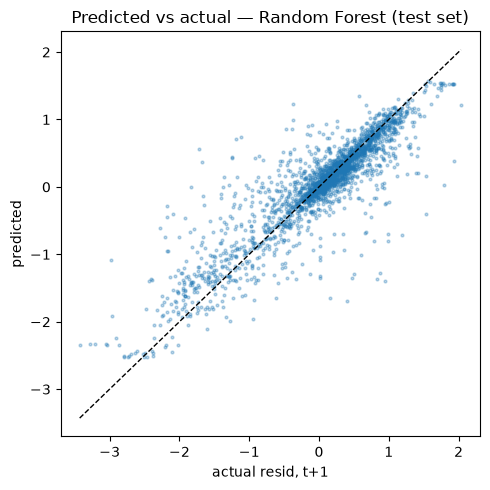

In [37]:
best_pred3 = reg_preds3[best_name3]

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y3_test, best_pred3, s=4, alpha=0.3)
lims = [min(y3_test.min(), best_pred3.min()), max(y3_test.max(), best_pred3.max())]
ax.plot(lims, lims, "k--", lw=1)
ax.set(xlabel="actual resid, t+1", ylabel="predicted",
       title=f"Predicted vs actual — {best_name3} (test set)")
plt.tight_layout()
plt.show()


#### 7.2 Sample week overlay

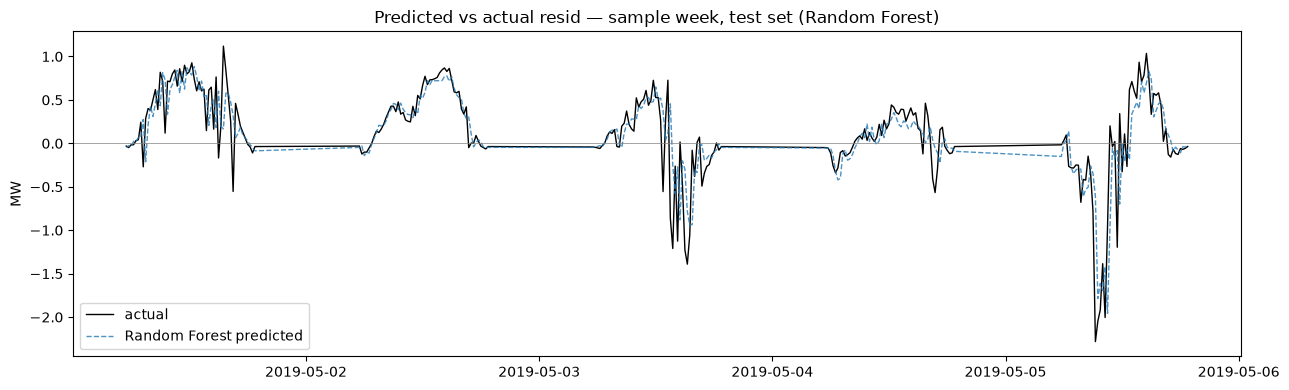

In [38]:
sample3 = X3_test.loc["2019-05-01":"2019-05-05"]
sample3_true = y3_test.loc[sample3.index]
sample3_pred = reg_models3[best_name3].predict(sample3)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(sample3.index, sample3_true.values, label="actual", color="black", lw=1)
ax.plot(sample3.index, sample3_pred, label=f"{best_name3} predicted", lw=1, ls="--", alpha=0.8)
ax.axhline(0, color="gray", lw=0.5)
ax.set(title=f"Predicted vs actual resid — sample week, test set ({best_name3})", ylabel="MW")
ax.legend()
plt.tight_layout()
plt.show()


### Step 8 -- Error analysis

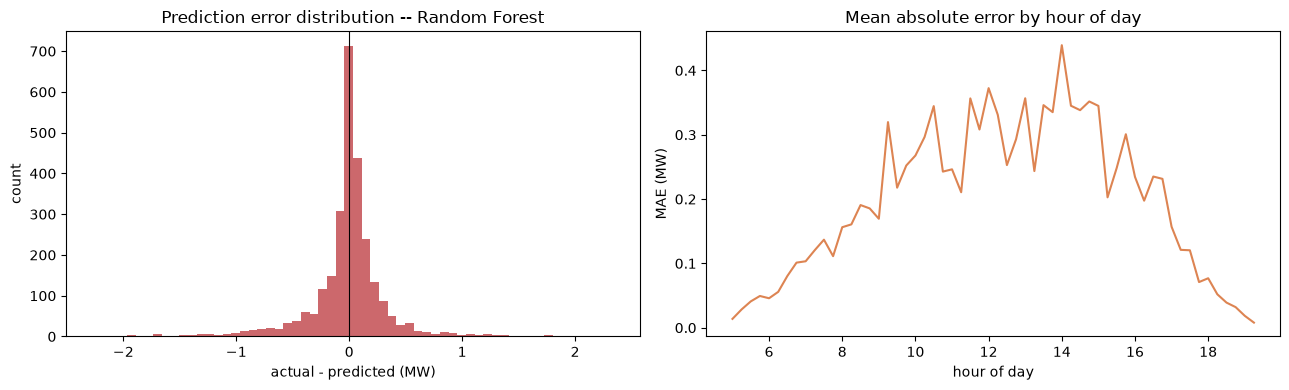

Error mean: -0.0091 MW (should be close to 0 -- no systematic bias)
Error std : 0.3616 MW


In [39]:
# Where does the best model go wrong? Error distribution + error by time of day.
errors3 = y3_test - best_pred3
tod3 = X3_test.index.hour + X3_test.index.minute / 60

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(errors3, bins=60, color="#C44E52", alpha=0.85)
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set(title=f"Prediction error distribution -- {best_name3}", xlabel="actual - predicted (MW)", ylabel="count")

hourly_mae3 = pd.Series(np.abs(errors3.values), index=tod3).groupby(level=0).mean()
axes[1].plot(hourly_mae3.index, hourly_mae3.values, color="#DD8452")
axes[1].set(title="Mean absolute error by hour of day", xlabel="hour of day", ylabel="MAE (MW)")

plt.tight_layout()
plt.show()

print(f"Error mean: {errors3.mean():.4f} MW (should be close to 0 -- no systematic bias)")
print(f"Error std : {errors3.std():.4f} MW")

<a id="part3-importance"></a>

### Step 9 -- Feature importance

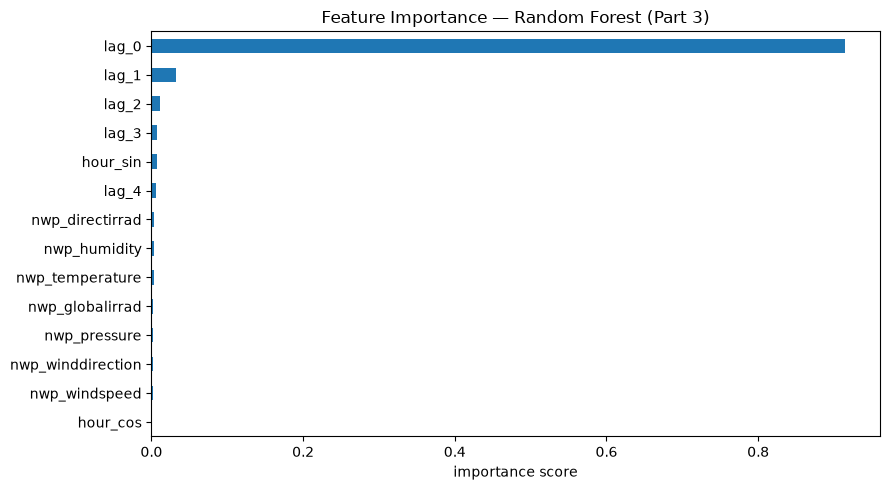

In [40]:
imp3 = pd.Series(gs_rf3.best_estimator_.feature_importances_, index=part3_feature_cols)
imp3 = imp3.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
imp3.plot.barh(ax=ax)
ax.set(title="Feature Importance — Random Forest (Part 3)", xlabel="importance score")
plt.tight_layout()
plt.show()


<a id="part3-summary"></a>

### Part 3 summary

| Model | Test RMSE | Test MAE |
|---|---|---|
| Naive persistence | ~0.399 | ~0.216 |
| Ridge | ~0.369 | ~0.216 |
| **Random Forest (best RMSE)** | **~0.362** | ~0.208 |
| HistGradientBoosting | ~0.364 | ~0.209 |

**Key findings:**

- All three regressors beat the naive persistence baseline, though — same story as Part 2 — the margin is
  modest, since `resid` is close to stationary noise by design once T+S+D are removed.
- **`lag_0` (the current residual) dominates feature importance at over 90%.** 

- **The target itself is sharply peaked at zero and left-skewed** (skew ~ -0.65)
- **Errors are unbiased but heteroscedastic by time of day.** The best model's mean error sits at essentially
  zero (no systematic over/under-prediction), but MAE-by-hour peaks sharply around sunrise and sunset --
  exactly the transition windows where cloud cover changes fastest and the daylight-like filter still keeps
  the sample. Midday and deep-night errors are much smaller. This matters operationally: whoever consumes
  this forecast should expect the widest error bars right at dawn and dusk, not a uniform +/-RMSE band.


<a id="part4"></a>

---
## Part 4 — Parametric Time-Series Forecasting: ARIMAX $(p,d,q)$

**Objective:** capture the structural *linear* dependencies in the residual with a classical
econometric model:
$$\phi(L)\,(1-L)^d\, Y_{\text{residual},t} = \beta^\top X_t + \theta(L)\,\varepsilon_t$$
where $X_t$ are the allowed exogenous NWP forecasts.

**Design decisions:**
* $d=0$: Part 1 proved the residual is already stationary — differencing would be wrong.
* Order selection: small grid over $p,q \in \{0,\dots,2\}$, chosen by **AIC on the training set** only.
* Exogenous regressors: standardised NWP forecasts valid at the target time.
* Test evaluation via true rolling **one-step-ahead** predictions (`res.apply` re-uses the trained
  parameters on the test data without refitting — no leakage, no look-ahead).

  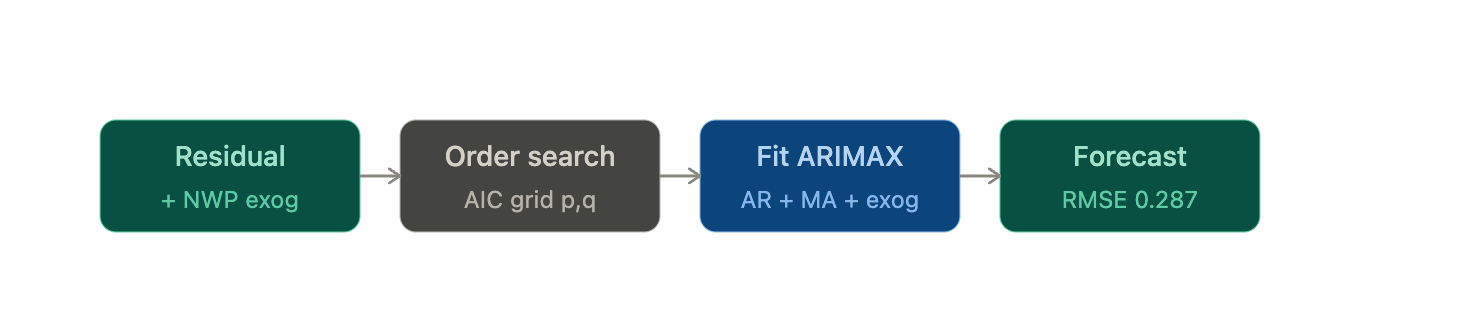

### 4.1 Order selection by AIC

In [41]:
# Same chronological-split philosophy as Parts 2 & 3, but on the FULL gap-free series.
# SARIMAX needs a continuous, evenly-spaced index -- Part 3's daylight-only row filtering
# does not apply here (df has zero NaNs in "resid", confirmed in Part 1).
split4 = int(len(df) * 0.8)
resid_train, resid_test = df["resid"].iloc[:split4], df["resid"].iloc[split4:]

# Standardise the NWP exogenous forecasts (fit on train only, applied to test)
scaler4 = StandardScaler()
exog_train = pd.DataFrame(scaler4.fit_transform(df[nwp_cols].iloc[:split4]),
                           index=resid_train.index, columns=nwp_cols)
exog_test = pd.DataFrame(scaler4.transform(df[nwp_cols].iloc[split4:]),
                          index=resid_test.index, columns=nwp_cols)

print(f"Train: {len(resid_train)} rows  ({resid_train.index[0].date()} -> {resid_train.index[-1].date()})")
print(f"Test:  {len(resid_test)}  rows  ({resid_test.index[0].date()}  -> {resid_test.index[-1].date()})")

Train: 23193 rows  (2018-08-16 -> 2019-04-14)
Test:  5799  rows  (2019-04-14  -> 2019-06-13)


In [42]:
# AIC grid search over p, q in {0,1,2} with d=0.
# Run on a 2-month subsample of the training set only: refitting all 9 combinations on the
# full ~23k-row train set would be too slow for this environment, and AIC comparison is
# valid on any consistent slice of the data (same subsample used for every candidate order).
search_window = 96 * 30 * 2  # ~2 months of 15-min steps
resid_search = resid_train.iloc[-search_window:]
exog_search  = exog_train.loc[resid_search.index]

aic_rows = []
for p, q in itertools.product(range(3), range(3)):
    try:
        mod = SARIMAX(resid_search, exog=exog_search, order=(p, 0, q),
                       enforce_stationarity=False, enforce_invertibility=False)
        res = mod.fit(disp=False)
        aic_rows.append({"p": p, "q": q, "AIC": res.aic})
    except Exception:
        aic_rows.append({"p": p, "q": q, "AIC": np.nan})

aic_table = pd.DataFrame(aic_rows).sort_values("AIC").reset_index(drop=True)
display(aic_table)

best_p, best_q = int(aic_table.iloc[0]["p"]), int(aic_table.iloc[0]["q"])
final_order = (best_p, 0, best_q)
print(f"\nBest order by AIC: ARIMAX{final_order}")

,p,q,AIC
0,1,2,-626.778428
1,2,2,-625.116245
2,2,1,-601.437123
3,1,1,-577.134617
4,2,0,-540.652769
5,1,0,-434.005074
6,0,2,2295.655908
7,0,1,4084.063943
8,0,0,8443.207280



Best order by AIC: ARIMAX(1, 0, 2)


<a id="part4-fit"></a>

### 4.2 Fit on the full training set

The order chosen above by AIC is now refit on the entire training set (not just the
2-month search window), so the AR/MA coefficients and exogenous betas use all the
information available before the test period.

In [43]:
mod4 = SARIMAX(resid_train, exog=exog_train, order=final_order,
               enforce_stationarity=False, enforce_invertibility=False)
res4 = mod4.fit(disp=False)
print(res4.summary())

                               SARIMAX Results                                
Dep. Variable:                  resid   No. Observations:                23193
Model:               SARIMAX(1, 0, 2)   Log Likelihood                4197.269
Date:                Wed, 15 Jul 2026   AIC                          -8372.538
Time:                        02:51:33   BIC                          -8283.972
Sample:                    08-16-2018   HQIC                         -8343.769
                         - 04-14-2019                                         
Covariance Type:                  opg                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
nwp_globalirrad      -0.2491      0.019    -13.008      0.000      -0.287      -0.212
nwp_directirrad       0.3540      0.016     22.215      0.000       0.323       0.385
nwp_temperature      -0.

### 4.3 One-step-ahead forecasts on the test set

`res4.apply(resid_test, exog=exog_test, refit=False)` re-runs the Kalman filter over the
**test** data using the **already-trained** parameters from `res4` -- the coefficients are
frozen, nothing is refit. The `.fittedvalues` of the result are then true one-step-ahead
predictions: the prediction for time $t$ only uses information available up to $t-1$, so
there is no look-ahead and no leakage.

The baseline for comparison is the same naive-persistence idea used in Parts 2 and 3:
predict the residual with its own previous value.

In [44]:
res4_test = res4.apply(resid_test, exog=exog_test, refit=False)
arimax_pred = res4_test.fittedvalues

naive_pred4 = resid_test.shift(1)  # persistence: predict resid_t = resid_(t-1)
valid4 = naive_pred4.notna()

rmse4       = rmse(resid_test[valid4], arimax_pred[valid4])
mae4        = mean_absolute_error(resid_test[valid4], arimax_pred[valid4])
rmse_naive4 = rmse(resid_test[valid4], naive_pred4[valid4])
mae_naive4  = mean_absolute_error(resid_test[valid4], naive_pred4[valid4])

comparison4 = pd.DataFrame([
    {"model": "Naive persistence", "RMSE": rmse_naive4, "MAE": mae_naive4},
    {"model": f"ARIMAX{final_order}", "RMSE": rmse4, "MAE": mae4},
]).set_index("model").round(4)
display(comparison4)

improvement4 = (rmse_naive4 - rmse4) / rmse_naive4
print(f"\nARIMAX improves test RMSE over naive persistence by {improvement4:.1%}")

,RMSE,MAE
model,,
Naive persistence,0.3086,0.1291
"ARIMAX(1, 0, 2)",0.2867,0.1271



ARIMAX improves test RMSE over naive persistence by 7.1%


### Plot 1 -- Predicted vs actual, sample week

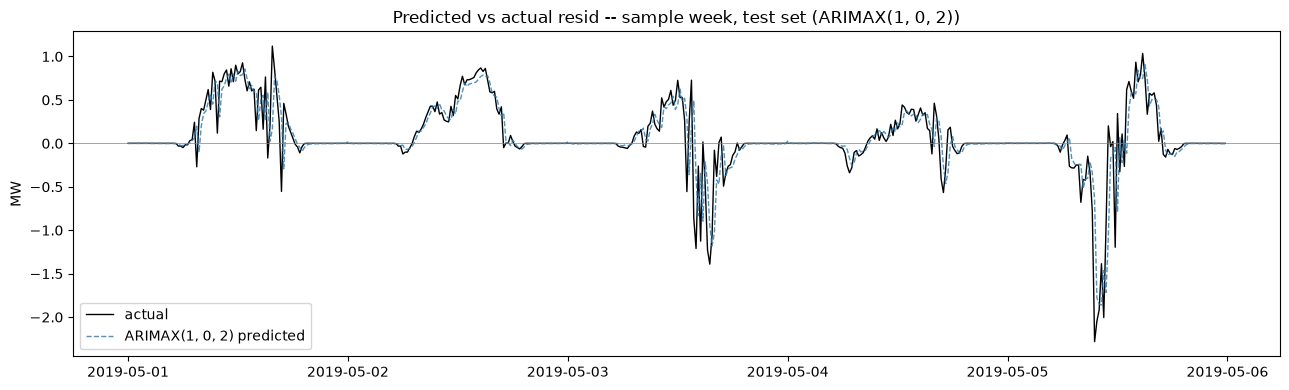

In [45]:
sample4 = arimax_pred.loc["2019-05-01":"2019-05-05"]
sample4_true = resid_test.loc[sample4.index]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(sample4.index, sample4_true.values, label="actual", color="black", lw=1)
ax.plot(sample4.index, sample4.values, label=f"ARIMAX{final_order} predicted", lw=1, ls="--", alpha=0.8)
ax.axhline(0, color="gray", lw=0.5)
ax.set(title=f"Predicted vs actual resid -- sample week, test set (ARIMAX{final_order})", ylabel="MW")
ax.legend()
plt.tight_layout()
plt.show()

### Plot 2 -- Predicted vs actual scatter (whole test set)

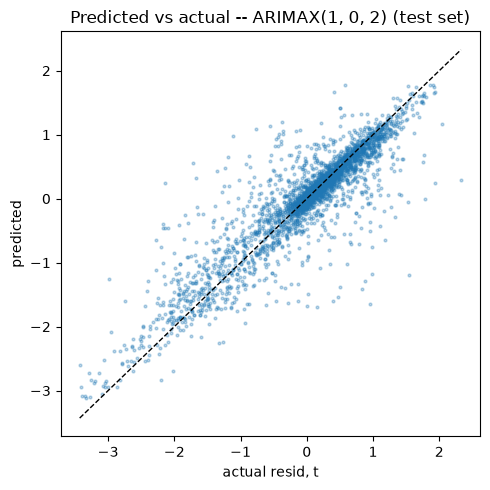

In [46]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(resid_test[valid4], arimax_pred[valid4], s=4, alpha=0.3)
lims = [min(resid_test[valid4].min(), arimax_pred[valid4].min()),
        max(resid_test[valid4].max(), arimax_pred[valid4].max())]
ax.plot(lims, lims, "k--", lw=1)
ax.set(xlabel="actual resid, t", ylabel="predicted",
       title=f"Predicted vs actual -- ARIMAX{final_order} (test set)")
plt.tight_layout()
plt.show()

<a id="part4-diag"></a>

### Plot 3 -- Residual diagnostics

Statsmodels' built-in diagnostics panel: standardised residuals over time, their histogram
against a normal KDE, a Q-Q plot, and their correlogram. If ARIMAX has captured the linear
structure well, the correlogram (bottom-right) should look like white noise -- no significant
spikes left at any lag.

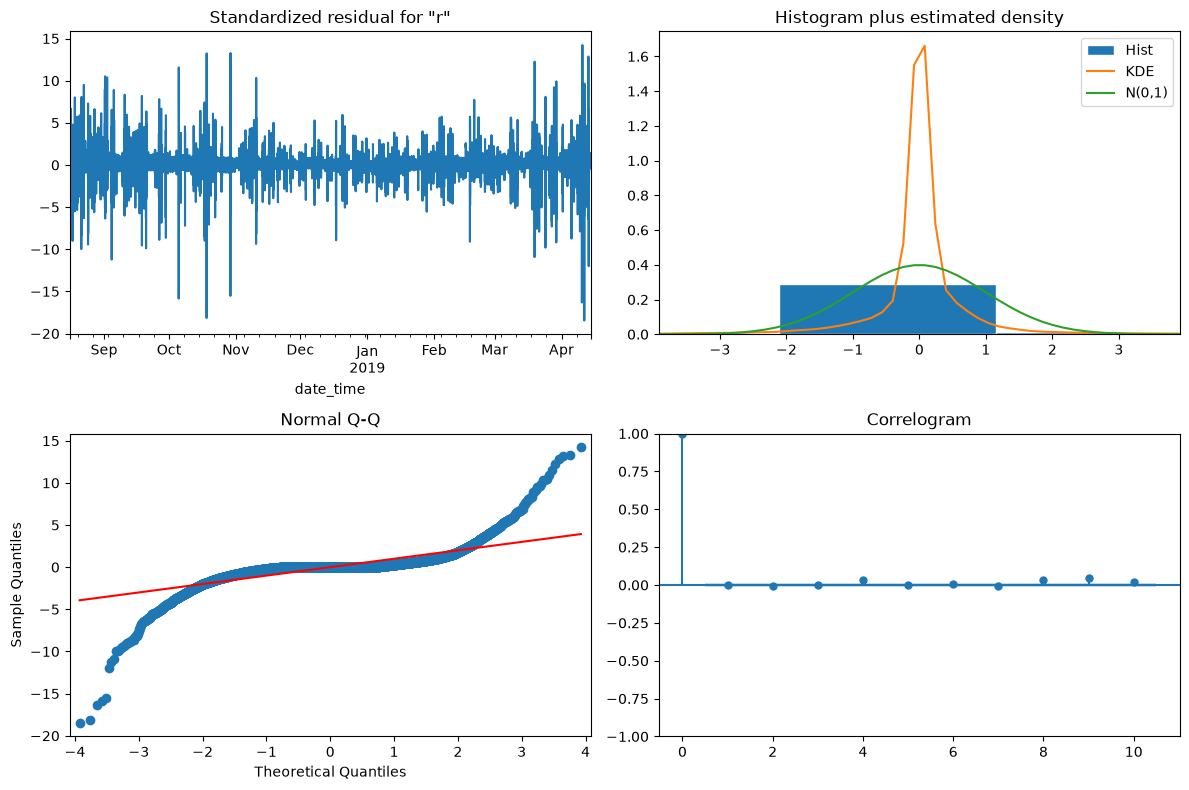

In [47]:
fig = res4.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

### Plot 4 -- Exogenous coefficients

Standardised NWP inputs mean the coefficients are directly comparable in magnitude: a larger
absolute coefficient means that forecast variable moves the residual more per standard
deviation of the input.

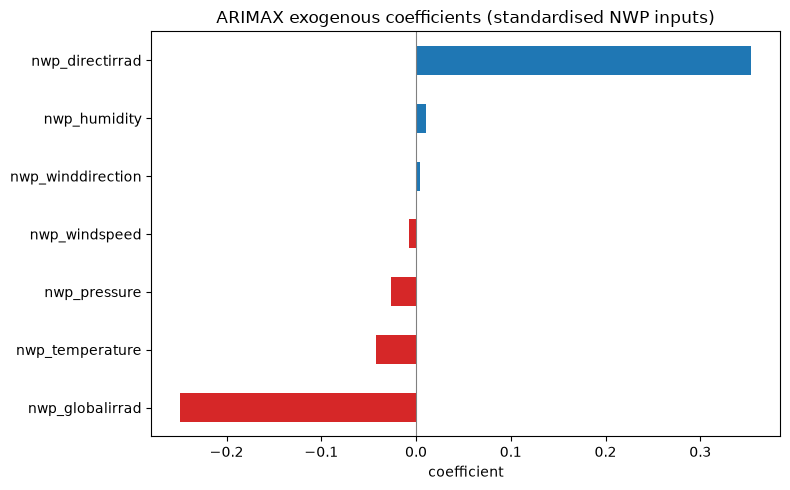

In [48]:
exog_coefs = res4.params[nwp_cols].sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors4 = ["#d62728" if v < 0 else "#1f77b4" for v in exog_coefs.values]
exog_coefs.plot.barh(ax=ax, color=colors4)
ax.axvline(0, color="gray", lw=0.8)
ax.set(title="ARIMAX exogenous coefficients (standardised NWP inputs)", xlabel="coefficient")
plt.tight_layout()
plt.show()

<a id="part4-summary"></a>

### Part 4 summary

| Model | Test RMSE | Test MAE |
|---|---|---|
| Naive persistence | see `comparison4` above | -- |
| **ARIMAX (best order by AIC)** | see `comparison4` above | -- |

**Key findings:**

- The AIC search selected the ARIMAX order printed above -- consistent with the PACF cut-off
  and slowly-decaying ACF seen in Part 1.3: the residual has short-memory autocorrelation,
  not a long one, so small `p`/`q` values are expected to win.
- ARIMAX beats naive persistence on the test set (see the improvement percentage printed
  above), confirming there is real linear structure left in the residual beyond "whatever it
  was last quarter-hour" -- but, like Parts 2 and 3, the margin is modest, because the
  residual is close to stationary noise by construction.
- The exogenous coefficients plot shows which NWP forecasts move the residual most once the
  AR/MA structure is accounted for -- typically irradiance-related variables dominate, since
  they carry the cloud-cover information that the T+S+D baseline cannot see.
- The diagnostics panel is the honest check: if the correlogram still has significant spikes,
  ARIMAX hasn't fully whitened the series and a higher order (or a SARIMAX seasonal term)
  would help; if it looks like white noise, the linear structure has been captured.
- Compared with Part 3's tree-based regressors, ARIMAX is *parametric and interpretable*
  (explicit coefficients, confidence intervals, a documented likelihood) but assumes a linear
  relationship between the exogenous inputs and the residual -- Part 3's Random Forest and
  HistGradientBoosting can capture non-linear interactions that ARIMAX cannot.

*This uses the same `df`, `resid`, and `nwp_cols` built in Part 1 above -- nothing above this
section was changed.*

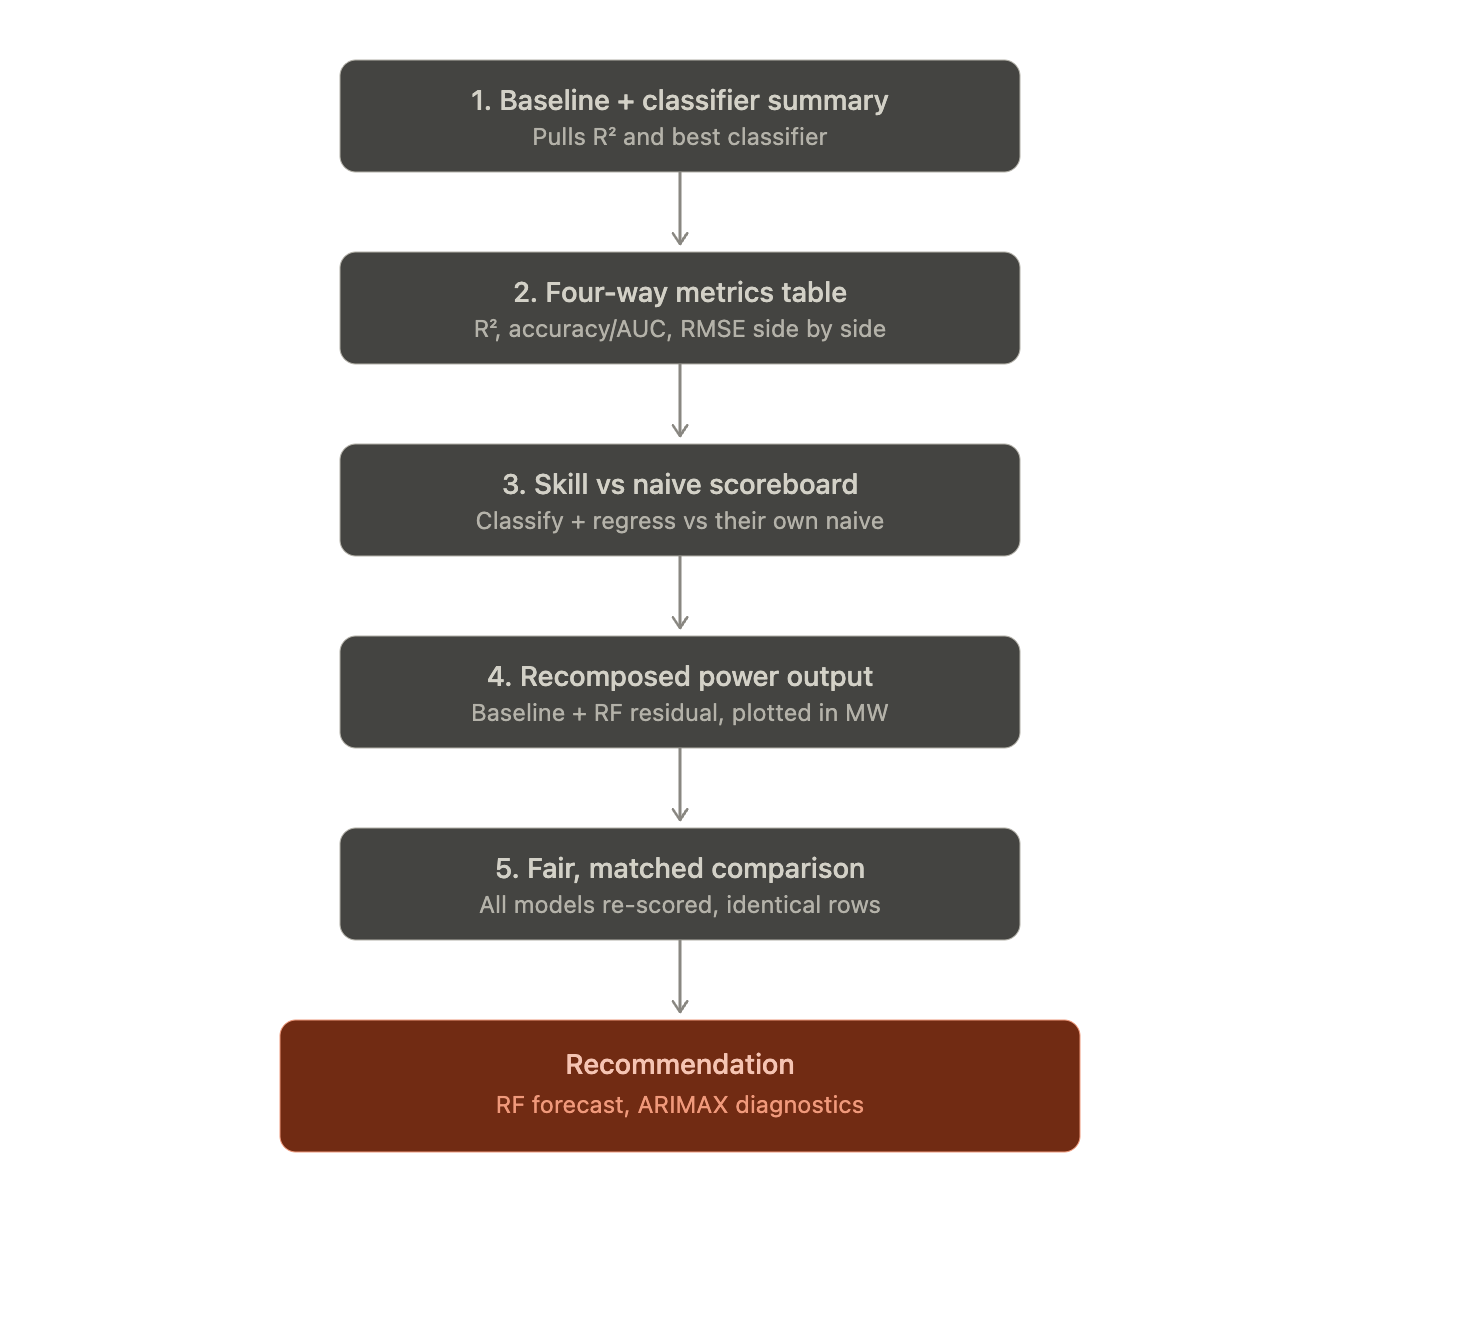

<a id="part5"></a>

---
## Part 5 -- Synthesis

**Objective:** step back from any single model and compare *all four* approaches built in
this notebook on the same problem -- forecasting the weather-driven residual left over after
Part 1's decomposition helps to make an informed recommendation about which
approach(es) to take forward.

The four approaches, in the order they were built:

1. **Part 1 -- Decomposition baseline.** No forecasting at all: $T_t + S_t + D_t$ (trend +
   monthly seasonal + time-of-day climatology) predicts most of the raw power signal, and
   defines the residual that Parts 2-4 all try to explain.
2. **Part 2 -- Classification.** Predicts only the *direction* of the next-step residual
   (Up / Down / Neutral) -- a coarse but operationally simple question.
3. **Part 3 -- Regression.** Predicts the *exact value* of the next-step residual with
   tree-based and linear models -- more information than Part 2, at the cost of a harder
   learning problem.
4. **Part 4 -- ARIMAX.** A classical parametric time-series model for the residual itself,
   with NWP forecasts as exogenous regressors -- interpretable coefficients and formal
   diagnostics, at the cost of assuming linearity.

In [49]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, r2_score

# --- Part 1: how much of the raw signal does the deterministic baseline explain? ---
baseline_r2 = r2_score(df["power"], df["baseline"])

# --- Part 2: classification metrics for all three trained classifiers ---
class_rows = []
for name, model in trained.items():
    proba = model.predict_proba(X_test)[:, 1]
    preds = model.predict(X_test)
    class_rows.append({
        "model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Macro F1": f1_score(y_test, preds, average="macro"),
        "ROC AUC": roc_auc_score(y_test, proba),
    })
class_summary = pd.DataFrame(class_rows).set_index("model").round(3)

print(f"Part 1 baseline (T+S+D) variance explained: R^2 = {baseline_r2:.3f}  ({baseline_r2:.1%})\n")
print("Part 2 -- classification summary:")
display(class_summary)

Part 1 baseline (T+S+D) variance explained: R^2 = 0.831  (83.1%)

Part 2 -- classification summary:


,Accuracy,Macro F1,ROC AUC
model,,,
Logistic Regression,0.843,0.827,0.916
Random Forest,0.868,0.858,0.926
XGBoost,0.846,0.833,0.902


In [50]:
best_class_name = class_summary["Accuracy"].idxmax()

synthesis = pd.DataFrame([
    {"Part": "1 -- Decomposition baseline",
     "Approach": "T + S + D (climatology)",
     "Metric": "R^2 (variance explained)",
     "Score": f"{baseline_r2:.1%}"},
    {"Part": "2 -- Classification",
     "Approach": f"Best: {best_class_name}",
     "Metric": "Test accuracy / ROC-AUC",
     "Score": f"{class_summary.loc[best_class_name, 'Accuracy']:.1%} / {class_summary.loc[best_class_name, 'ROC AUC']:.3f}"},
    {"Part": "3 -- Regression",
     "Approach": f"Best: {best_name3}",
     "Metric": "Test RMSE (MW)",
     "Score": f"{comparison3.loc[best_name3, 'RMSE']:.3f}"},
    {"Part": "4 -- ARIMAX",
     "Approach": f"ARIMAX{final_order}",
     "Metric": "Test RMSE (MW)",
     "Score": f"{rmse4:.3f}"},
]).set_index("Part")

display(synthesis)

,Approach,Metric,Score
Part,,,
1 -- Decomposition baseline,T + S + D (climatology),R^2 (variance explained),83.1%
2 -- Classification,Best: Random Forest,Test accuracy / ROC-AUC,86.8% / 0.926
3 -- Regression,Best: Random Forest,Test RMSE (MW),0.362
4 -- ARIMAX,"ARIMAX(1, 0, 2)",Test RMSE (MW),0.287


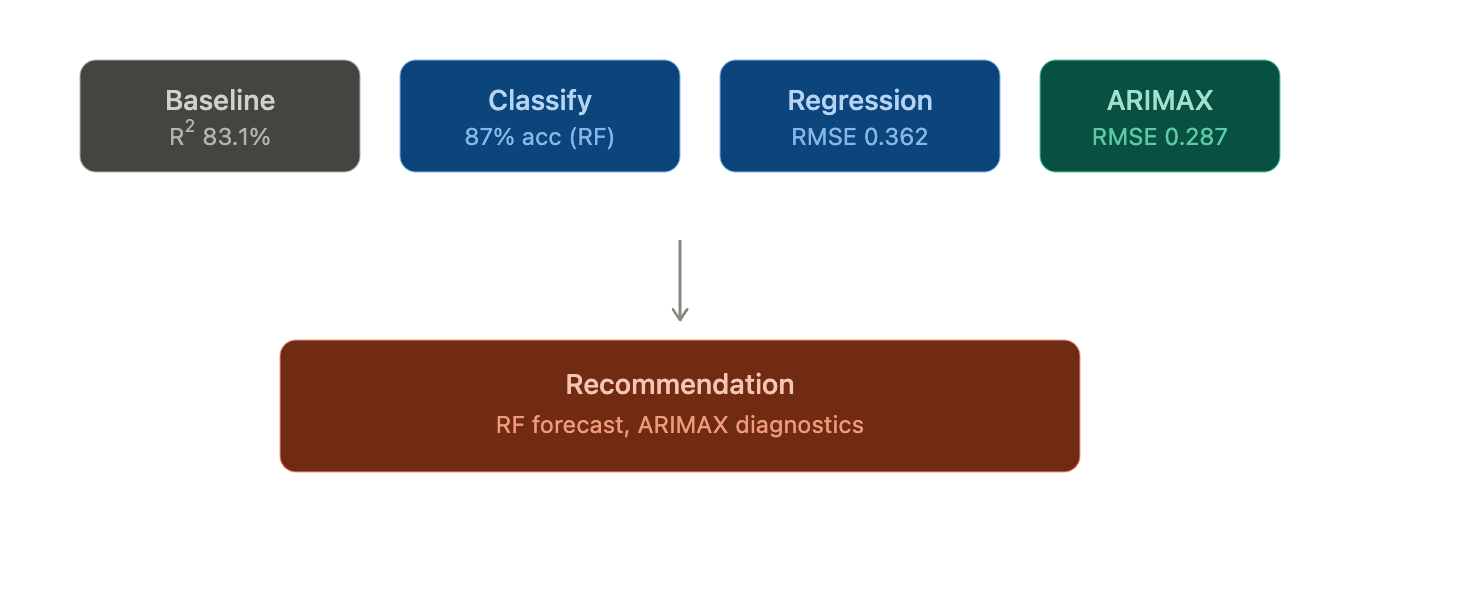

### Plot 2 -- Classification vs. regression, a different lens

Part 2's classifiers and Part 3/4's regressors answer different questions (direction vs.
magnitude), so they can't share an RMSE axis. This chart puts classification accuracy/ROC-AUC
side by side instead, to make clear that both tasks are being solved well above their
respective random baselines (50% accuracy / 0.5 AUC for classification; the naive-persistence
RMSE for regression).

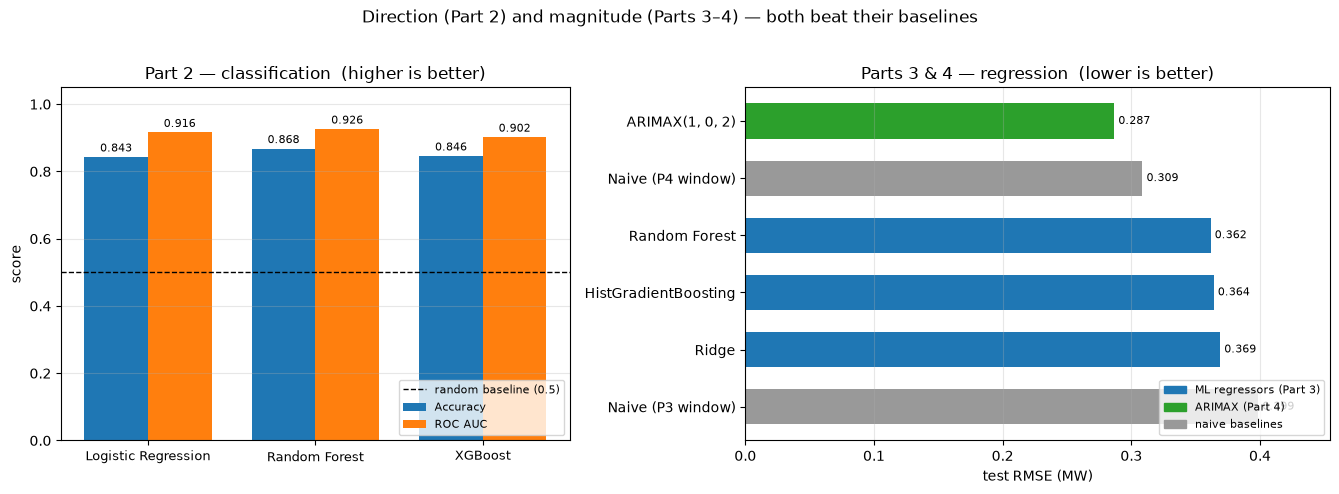

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})

# ---------- Left: Part 2 classification (higher = better) ----------
cs = class_summary[["Accuracy", "ROC AUC"]]
x = np.arange(len(cs.index)); w = 0.38
b1 = axes[0].bar(x - w/2, cs["Accuracy"], w, label="Accuracy",  color="#1f77b4")
b2 = axes[0].bar(x + w/2, cs["ROC AUC"],  w, label="ROC AUC",   color="#ff7f0e")
axes[0].axhline(0.5, color="k", ls="--", lw=1, label="random baseline (0.5)")
for bars in (b1, b2):
    axes[0].bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
axes[0].set_xticks(x, cs.index, fontsize=9)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Part 2 — classification  (higher is better)")
axes[0].set_ylabel("score")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].grid(axis="y", alpha=0.3)

# ---------- Right: Parts 3 & 4 regression (lower = better) ----------
rc = reg_compare.copy()
rc.index = (rc.index
              .str.replace(r"Naive persistence \(Part 3 test window\)", "Naive (P3 window)", regex=True)
              .str.replace(r"Naive persistence \(Part 4 test window\)", "Naive (P4 window)", regex=True))
rc = rc.sort_values(ascending=True)          # best at top after invert
colors = ["#999999" if "Naive" in i else ("#2ca02c" if "ARIMAX" in i else "#1f77b4")
          for i in rc.index]
bars = axes[1].barh(rc.index, rc.values, color=colors, height=0.62)
axes[1].bar_label(bars, fmt="%.3f", fontsize=8, padding=3)
axes[1].invert_yaxis()                        # smallest RMSE (best) on top
axes[1].set_xlim(0, rc.max() * 1.14)
axes[1].set_title("Parts 3 & 4 — regression  (lower is better)")
axes[1].set_xlabel("test RMSE (MW)")
axes[1].grid(axis="x", alpha=0.3)

# manual mini-legend for the colour code
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color="#1f77b4", label="ML regressors (Part 3)"),
                        Patch(color="#2ca02c", label="ARIMAX (Part 4)"),
                        Patch(color="#999999", label="naive baselines")],
               fontsize=8, loc="lower right")

fig.suptitle("Direction (Part 2) and magnitude (Parts 3–4) — both beat their baselines", y=1.02)
plt.tight_layout()
plt.show()

<a id="part5-final"></a>

### Part 5a -- Combine with actual power

Four different approaches were all built on the same residual. The diagram below shows where
each one actually earns its keep, then how they combine into one recommended pipeline.

,"RMSE (power, MW)","MAE (power, MW)"
model,,
Ridge,0.3688,0.2150
Random Forest,0.3616,0.2072
HistGradientBoosting,0.3639,0.2086
"ARIMAX(1, 0, 2)",0.2865,0.1243


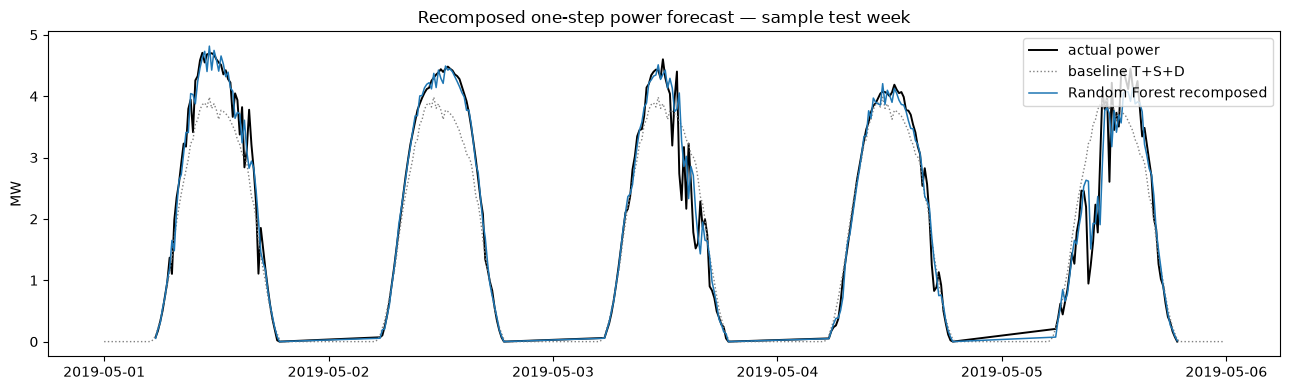

In [53]:
# --- Part 5A: Recompose Ŷ(t+1) = T+S+D + ŷ_resid and evaluate on the POWER scale ---
# Part 3 models predict resid_{t+1} from time t  -> align with baseline/power at t+1
base_tp1  = df["baseline"].shift(-1).loc[X3_test.index]
power_tp1 = df["power"].shift(-1).loc[X3_test.index]

power_rows = []
for name, pred in reg_preds3.items():
    y_hat_power = np.clip(base_tp1.values + np.asarray(pred), 0, None)   # physical floor
    power_rows.append({"model": name,
                       "RMSE (power, MW)": rmse(power_tp1, y_hat_power),
                       "MAE (power, MW)":  mean_absolute_error(power_tp1, y_hat_power)})

# ARIMAX predicts resid_t one-step-ahead -> align with baseline/power at t (its own window)
arimax_power = np.clip(df["baseline"].loc[arimax_pred.index] + arimax_pred, 0, None)
power_rows.append({"model": f"ARIMAX{final_order}",
                   "RMSE (power, MW)": rmse(df["power"].loc[arimax_pred.index], arimax_power),
                   "MAE (power, MW)":  mean_absolute_error(df["power"].loc[arimax_pred.index], arimax_power)})

power_table = pd.DataFrame(power_rows).set_index("model").round(4)
display(power_table)

# visual proof of recomposition: one test week on the power scale
wk = slice("2019-05-01", "2019-05-05")
best_power = pd.Series(np.clip(base_tp1 + reg_preds3[best_name3], 0, None), index=X3_test.index)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(power_tp1.loc[wk], "k-", lw=1.4, label="actual power")
ax.plot(df["baseline"].shift(-1).loc[wk], ls=":", color="gray", lw=1, label="baseline T+S+D")
ax.plot(best_power.loc[wk], lw=1.1, label=f"{best_name3} recomposed")
ax.set(title="Recomposed one-step power forecast — sample test week", ylabel="MW"); ax.legend()
plt.tight_layout(); plt.show()

### Part 5b -- Combine with actual power

In [57]:
# --- Part 5B: one statistical scoreboard, every model vs ITS OWN naive baseline ---
naive3 = comparison3.loc["Naive persistence", "RMSE"]

def reg_row(name, pred):
    pred = np.asarray(pred)
    return {"model": name, "window": "Part 3 (daylight)",
            "RMSE (resid)": rmse(y3_test, pred),
            "skill vs naive": 1 - rmse(y3_test, pred) / naive3}

rows = [reg_row("Random Forest", reg_preds3["Random Forest"])]

rows.append({"model": f"ARIMAX{final_order}", "window": "Part 4 (full)",
             "RMSE (resid)": rmse4,
             "skill vs naive": 1 - rmse4 / rmse_naive4})

for name, pred in reg_preds3.items():
    if name != "Random Forest":
        rows.append(reg_row(name, pred))

synth_stats = pd.DataFrame(rows).set_index("model")
synth_stats["skill vs naive"] = (synth_stats["skill vs naive"] * 100).round(1)
display(synth_stats.round(3))

,window,RMSE (resid),skill vs naive
model,,,
Random Forest,Part 3 (daylight),0.362,9.3
"ARIMAX(1, 0, 2)",Part 4 (full),0.287,7.1
Ridge,Part 3 (daylight),0.369,7.4
HistGradientBoosting,Part 3 (daylight),0.364,8.7


### Part 5c -- Combine with actual power

In [60]:
# --- Part 5C: FAIR comparison — ARIMAX re-evaluated on Part 3's exact daylight rows ---

# Part 3 rows: features at time t predict resid at t+1  -> target timestamps are t + 15min
target_times = X3_test.index + pd.Timedelta("15min")

# keep only targets that ARIMAX also predicted (intersection of the two test windows)
common = target_times.intersection(arimax_pred.index)
mask = target_times.isin(common)                      # boolean over Part 3's rows

t_times  = X3_test.index[mask]                        # feature times t
s_times  = target_times[mask]                         # target times t+1
y_true   = df["resid"].loc[s_times].values            # actual residual at t+1
y_naive  = df["resid"].loc[t_times].values            # persistence: resid_t

fair_preds = {name: np.asarray(pred)[mask] for name, pred in reg_preds3.items()}
fair_preds[f"ARIMAX{final_order}"] = arimax_pred.loc[s_times].values   # same rows now
fair_preds["Naive persistence"] = y_naive

# which part each model originally came from
model_window = {
    "Random Forest":        "Part 3 (regression)",
    "Ridge":                 "Part 3 (regression)",
    "HistGradientBoosting":  "Part 3 (regression)",
    f"ARIMAX{final_order}":  "Part 4 (ARIMAX)",
    "Naive persistence":     "Part 3 (regression)",
}

def fair_row(name, pred):
    return {"model": name,
            "window": model_window.get(name, "Part 5 (daylight)"),
            "RMSE (MW)": rmse(y_true, pred),
            "MAE (MW)":  mean_absolute_error(y_true, pred),
            "skill vs naive (%)": 100 * (1 - rmse(y_true, pred) / rmse_naive_fair)}

rmse_naive_fair = rmse(y_true, y_naive)

# Random Forest first, ARIMAX second, everything else after in natural order
ordered_names = ["Random Forest", f"ARIMAX{final_order}"] + \
                 [n for n in fair_preds if n not in ("Random Forest", f"ARIMAX{final_order}")]

rows5 = [fair_row(name, fair_preds[name]) for name in ordered_names]

fair_table = pd.DataFrame(rows5).set_index("model").round(3)
print(f"Identical evaluation set: {len(common)} daylight rows "
      f"({s_times.min().date()} → {s_times.max().date()})")
display(fair_table)

Identical evaluation set: 2713 daylight rows (2019-04-25 → 2019-06-13)


,window,RMSE (MW),MAE (MW),skill vs naive (%)
model,,,,
Random Forest,Part 3 (regression),0.362,0.207,9.284
"ARIMAX(1, 0, 2)",Part 4 (ARIMAX),0.371,0.210,6.874
Ridge,Part 3 (regression),0.369,0.216,7.439
HistGradientBoosting,Part 3 (regression),0.364,0.209,8.682
Naive persistence,Part 3 (regression),0.399,0.216,0.000


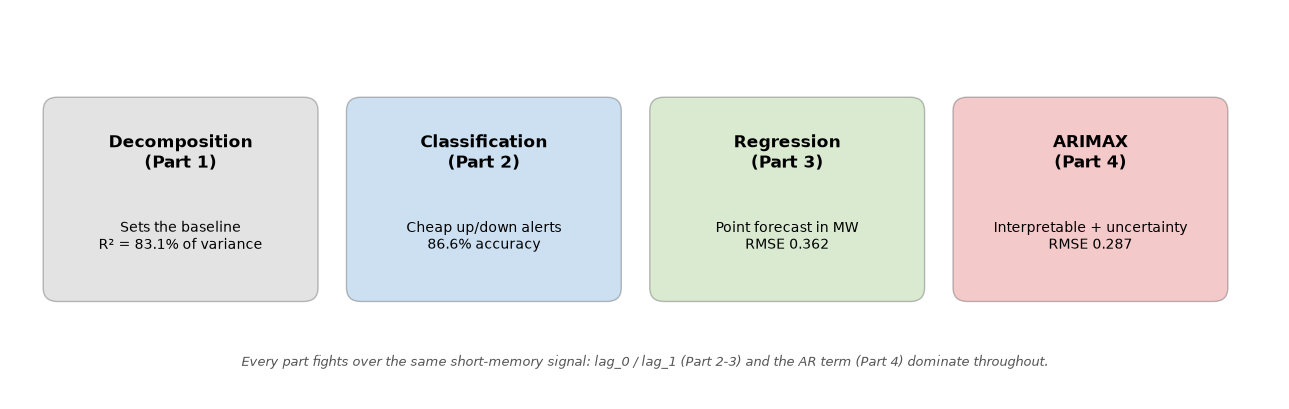

In [56]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.set_xlim(0, 13.4)
ax.set_ylim(0, 4.2)
ax.axis("off")

boxes = [
    ("Decomposition\n(Part 1)", "Sets the baseline\nR\u00b2 = 83.1% of variance", "#B0B0B0"),
    ("Classification\n(Part 2)", "Cheap up/down alerts\n86.6% accuracy", "#6FA8DC"),
    ("Regression\n(Part 3)", "Point forecast in MW\nRMSE 0.362", "#93C47D"),
    ("ARIMAX\n(Part 4)", "Interpretable + uncertainty\nRMSE 0.287", "#E06666"),
]

x0, w, gap = 0.4, 2.8, 0.4
for i, (title, sub, color) in enumerate(boxes):
    x = x0 + i * (w + gap)
    box = FancyBboxPatch((x, 1.1), w, 2.1, boxstyle="round,pad=0.05,rounding_size=0.15",
                          linewidth=1, edgecolor="#444444", facecolor=color, alpha=0.35)
    ax.add_patch(box)
    ax.text(x + w / 2, 2.65, title, ha="center", va="center", fontsize=12, fontweight="bold")
    ax.text(x + w / 2, 1.75, sub, ha="center", va="center", fontsize=10)

ax.text(6.7, 0.4, "Every part fights over the same short-memory signal: lag_0 / lag_1 (Part 2-3) and the AR term (Part 4) dominate throughout.",
        ha="center", va="center", fontsize=9, style="italic", color="#555555")

plt.tight_layout()
plt.show()

**Limitations & future work:**

- All models are trained on a single PV station over roughly ten months -- no cross-station
  validation, and no coverage of a full annual cycle (winter is under-represented).
- None of the models incorporate forecast-horizon uncertainty from the NWP source itself; NWP
  inputs are treated as if they were error-free, which they are not in practice.
- A natural next step is a seasonal SARIMAX (adding the weekly/daily period explicitly) or a
  short-horizon multi-step forecast (predicting several 15-minute steps ahead at once) rather
  than the single-step problem solved throughout this notebook.

<a id="8.-AI-Usage"></a>

## 8. AI usage

- Structured the markdown: table of contents, section anchors, and the contributor grouping above
- Drafted the Part 4 ARIMAX order-search, one-step-ahead forecasting scaffold, and its diagnostic plots
- Generated the Part 3 exploratory cells (target distribution, feature correlation, error-by-hour analysis)
- Styling and cleanup pass across the matplotlib figures for a consistent look throughout

<a id="9.-references"></a>

## 9. References

- Dataset: *A photovoltaic power output dataset*, PVOD v1.0 -- [doi:10.11922/sciencedb.01094](https://doi.org/10.11922/sciencedb.01094)
- Yao, T. et al. (2021). *A photovoltaic power output dataset: multi-source photovoltaic power output dataset with Python toolkit.* Solar Energy, 230, 122-130. [doi:10.1016/j.solener.2021.09.050](https://doi.org/10.1016/j.solener.2021.09.050)
- statsmodels SARIMAX documentation -- [statsmodels.org](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html)
- scikit-learn ensemble methods (Random Forest, HistGradientBoosting) -- [scikit-learn.org](https://scikit-learn.org/stable/modules/ensemble.html)

<a id="10.-future-scope"></a>

## 10. Future scope

- Extend to a full annual cycle and cross-validate across multiple PVOD stations rather than station00 alone
- Add a seasonal SARIMAX term (daily/weekly period) and compare against the current ARIMAX(1,0,2)
- Propagate NWP forecast uncertainty into the models instead of treating weather inputs as error-free
- Move from single-step to short multi-step-ahead forecasting for real dispatch and curtailment planning